# CAI 421: Where does RED-CNN denoising make liver CT images worse?

Low-dose CT is safer for the patient, but the images are noisier, so denoising models like RED-CNN are used to clean them. The problem is that a denoiser can also change the image in places where it shouldn't, and this could hide or fake small details like cysts and lesions.

So our question is: **can we train a model that finds the liver regions where RED-CNN moves the image further away from the full-dose reference?**

**What we did in this notebook**
1. Reviewed the candidate lesion slices (accept / reject) and kept the slices where the liver is clearly visible.
2. Got the liver masks using TotalSegmentator.
3. Ran the pretrained external RED-CNN on the low-dose slices.
4. Made pseudo-labels: a liver pixel is labeled 1 if RED-CNN increased its error by more than 4 HU.
5. Trained our model (RiskMapUNet) with 5-fold cross-validation split by patient, and compared it with two baselines, Attention U-Net and ResDUNet.

**To run it:** attach the private Kaggle dataset with the `CAI421_processed` folders, plus the external `RED-CNN/networks.py` and the `REDCNN_100000iter.ckpt` checkpoint. Run the cells in order. All outputs are saved in `/kaggle/working`.

**Limitation:** our labels are based on the change in error, not on tumor boundaries confirmed by a radiologist, so the results show where the image changed, not real clinical damage.



# - Libraries

In [54]:
import gc
import math
import random
import shutil
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

import nibabel as nib
from nibabel.processing import resample_from_to
from scipy.ndimage import label, sobel
from skimage.registration import phase_cross_correlation
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from IPython.display import display, Image
import random, gc, json, shutil
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

## Part 1: Accept / reject review of the candidate lesions (the 88 and 55 lesions)

> Examples of an accepted and a rejected case. We decided based on how the liver looked in the slice.

In [ ]:
root = "/kaggle/working/CAI421_processed"
df = pd.read_csv("/kaggle/working/liver_review/automatic_liver_review.csv")

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, decision in enumerate(["accept", "reject"]):
    row = df[df.decision.eq(decision)].iloc[0]
    z = int(row.confirmed_slice_index if decision == "accept" else row.suggested_slice_index)

    with np.load(f"{root}/pairs/{row.case_id}.npz") as f:
        images = [f["low"][z], f["full"][z]]
    with np.load(f"{root}/denoised_red_cnn/{row.case_id}.npz") as f:
        images.insert(1, f["denoised"][z])

    for ax, image, name in zip(axes[i], images, ["Low", "RED-CNN", "Full"]):
        ax.imshow(image, cmap="gray")
        ax.set_title(f"{decision.title()} | {name} | {row.case_id} | {z}")
        ax.axis("off")

plt.tight_layout()
plt.show()

**Important:**  run this cell first the rest of the notebook depends on it.

In [ ]:
INPUT = Path("/kaggle/input")
WORK = Path("/kaggle/working/CAI421_results")
WORK.mkdir(parents=True, exist_ok=True)
ROOT = Path("/kaggle/working/CAI421_processed")
ROOT.mkdir(parents=True, exist_ok=True)
source_roots = sorted(p for p in INPUT.rglob("CAI421_processed")if p.is_dir())
print("Source folders found:", len(source_roots))
assert len(source_roots) == 6, (f"Expected 6 folders, found {len(source_roots)}")
for source in source_roots:
    print("Merging:", source.parent.name)
    for file in source.rglob("*"):
        if not file.is_file():
            continue
        relative_path = file.relative_to(source)
        destination = ROOT / relative_path
        destination.parent.mkdir(parents=True, exist_ok=True)
        if not destination.exists():
            shutil.copy2(file, destination)
print("\nMerge completed!")

In [9]:
ROOT = Path("/kaggle/working/CAI421_processed")
DATA = ROOT / "student1_handoff"
REPORT = Path("/kaggle/working/dataset_audit")
REPORT.mkdir(parents=True, exist_ok=True)
manual = pd.read_csv(DATA / "manual_slice_review_FINAL_20261029_1317.csv")
source = pd.read_csv(DATA / "annotations_source_audit.csv")
print("Manual decisions:")
print(manual["decision"].value_counts())
print("\nManual review columns:")
print(manual.columns.tolist())
print("\nSource columns:")
print(source.columns.tolist())
approved = manual[manual["decision"].eq("approve")].copy()
print("\nApproved:", len(approved))
display(approved.head())

Manual decisions:
decision
reject     48
approve    40
Name: count, dtype: int64

Manual review columns:
['case_id', 'lesion_id', 'snapshot', 'suggested_index', 'decision', 'confirmed_slice_index', 'reviewer', 'evidence_notes']

Source columns:
['case_id', 'lesion_id', 'diagnosis_code', 'diagnosis', 'manufacturer', 'series_role', 'location_raw', 'snapshot', 'parsed', 'radius_px', 'x', 'y', 'slice_no', 'usable']

Approved: 40


,case_id,lesion_id,snapshot,suggested_index,decision,confirmed_slice_index,reviewer,evidence_notes
0,L004,1,L004_1.jpg,73,approve,74.0,rama,"Liver outline, spine, stomach air, and vessels..."
1,L004,2,L004_2.jpg,77,approve,77.0,rama,"Spine, liver outline, stomach air, and vessels..."
2,L004,3,L004_3.jpg,44,approve,44.0,rama,"Spine, kidneys, liver outline, and abdominal v..."
3,L004,4,L004_4.jpg,72,approve,72.0,rama,"Liver outline, spine, stomach air, and hepatic..."
5,L014,1,L014_1.jpg,119,approve,119.0,rama,"Liver outline, spine, stomach air, and vessels..."


In [ ]:
root = Path("/kaggle/working/CAI421_processed")
folder = Path("/kaggle/working/liver_review")

manual = pd.read_csv(root / "student1_handoff/manual_slice_review_FINAL_20261029_1317.csv")
auto = pd.read_csv(folder / "automatic_liver_review.csv")

manual = manual.loc[manual.decision.eq("approve"),
                    ["case_id", "confirmed_slice_index"]]
auto = auto.loc[auto.decision.eq("accept"),
                ["case_id", "confirmed_slice_index"]]

combined = pd.concat([manual, auto], ignore_index=True)
combined = combined.dropna().drop_duplicates().reset_index(drop=True)
combined["confirmed_slice_index"] = combined["confirmed_slice_index"].astype(int)

combined.to_csv(folder / "final_liver_slices.csv", index=False)

print("Manual approved:", len(manual))
print("Automatic accepted:", len(auto))
print("Unique combined slices:", len(combined))
print("Patients:", combined.case_id.nunique())
print("Saved:", folder / "final_liver_slices.csv")

Checking what the liver masks look like on the accepted slices, using a tool called TotalSegmentator.

In [11]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "TotalSegmentator"], check=True)
from totalsegmentator.python_api import totalsegmentator
print("TotalSegmentator installed successfully")

TotalSegmentator installed successfully


In [14]:
root = Path("/kaggle/working/CAI421_processed")
out = root / "totalseg_final"
out.mkdir(exist_ok=True)
df = pd.read_csv("/kaggle/working/liver_review/final_liver_slices.csv")
df = df.rename(columns={"slice": "confirmed_slice_index"})
records = []
for case, group in df.groupby("case_id"):
    with np.load(root / "pairs_raw_hu" / f"{case}.npz") as f:
        hu = f["full_hu"].astype(np.float32)
        pos = f["positions"].astype(float)
    with np.load(root / "pairs" / f"{case}.npz") as f:
        xy = f["pixel_spacing"].astype(float)
    delta = np.diff(pos, axis=0)
    dz = float(np.median(delta[:, 2]))
    assert hu.shape[0] == len(pos)
    assert hu.shape[1:] == (512, 512)
    assert len(delta) > 0 and abs(dz) > 0.1
    assert np.isfinite(hu).all() and np.isfinite(pos).all()
    assert np.all(xy > 0) and np.isfinite(xy).all()
    assert np.max(abs(delta[:, :2])) < 0.1
    assert np.max(abs(delta[:, 2] - dz)) < 0.1
    affine = np.array([[-xy[1], 0, 0, -pos[0, 0]],[0, -xy[0], 0, -pos[0, 1]],[0, 0, dz, pos[0, 2]],[0, 0, 0, 1]])
    nii = nib.Nifti1Image(hu.transpose(2, 1, 0), affine)
    result = totalsegmentator(
        nii, task="total", roi_subset=["liver"],
        device="gpu" if torch.cuda.is_available() else "cpu",
        quiet=True)
    if isinstance(result, dict):
        result = result["liver"]
    if result.shape != nii.shape or not np.allclose(result.affine, nii.affine):
        result = resample_from_to(result, nii, order=0)
    mask = (np.asarray(result.dataobj) > 0).transpose(2, 1, 0)
    components, _ = label(mask, structure=np.ones((3, 3, 3)))
    sizes = np.bincount(components.ravel())
    sizes[0] = 0
    mask = components == sizes.argmax()
    z = sorted(group.confirmed_slice_index.astype(int).unique())
    assert mask.shape == hu.shape and min(z) >= 0 and max(z) < len(mask)
    selected = mask[z].astype(np.uint8)
    np.savez_compressed(
        out / f"{case}.npz",
        slices=np.array(z),
        mask=selected)
    for index, pixels in zip(z, selected.sum(axis=(1, 2))):
        records.append([case, index, int(pixels)])
    print(f"{case}: {len(z)} slices saved")
qc = pd.DataFrame(records, columns=["case_id", "slice", "liver_pixels"])
qc["has_liver"] = qc.liver_pixels > 0
qc.to_csv(out / "mask_qc.csv", index=False)
print("\nTotal slices:", len(qc))
print("With liver:", qc.has_liver.sum())
print("Without liver:", (~qc.has_liver).sum())
print("Saved:", out)

L004: 4 slices saved
L014: 1 slices saved
L033: 1 slices saved
L057: 2 slices saved
L058: 1 slices saved
L064: 8 slices saved
L075: 2 slices saved
L077: 2 slices saved
L081: 6 slices saved
L110: 2 slices saved
L114: 1 slices saved
L123: 2 slices saved
L131: 4 slices saved
L160: 2 slices saved
L219: 1 slices saved
L220: 4 slices saved

Total slices: 43
With liver: 43
Without liver: 0
Saved: /kaggle/working/CAI421_processed/totalseg_final


Now we run the external RED-CNN (a CT denoising model) on our 41 samples.

In [16]:
root = Path("/kaggle/working/CAI421_processed")
repo = Path("/kaggle/working/RED-CNN")
out = root / "external_redcnn_final"
out.mkdir(exist_ok=True)
if not (repo / "networks.py").exists():
    subprocess.run(["git", "clone", "--depth", "1","https://github.com/SSinyu/RED-CNN.git", str(repo)], check=True)
ckpts = list(repo.rglob("REDCNN_100000iter.ckpt"))
ckpts += list(Path("/kaggle/input").rglob("REDCNN_100000iter.ckpt"))
if not ckpts:
    raise FileNotFoundError("External pretrained checkpoint not found.")
sys.path.insert(0, str(repo))
nn.Conv2D, nn.ConvTranspose2D = nn.Conv2d, nn.ConvTranspose2d
from networks import RED_CNN
device = "cuda" if torch.cuda.is_available() else "cpu"
model = RED_CNN().to(device)
model.load_state_dict(torch.load(ckpts[0], map_location="cpu", weights_only=True),strict=True)
model.eval()
df = pd.read_csv("/kaggle/working/liver_review/final_liver_slices.csv")
records = []
for case, group in df.groupby("case_id"):
    with np.load(root / "pairs_raw_hu" / f"{case}.npz") as f:
        keys = list(f.files)
        candidates = [k for k in ("low_hu", "low", "ldct") if k in keys]
        if not candidates:
            raise KeyError(f"{case}: unknown raw-HU keys {keys}")
        low = f[candidates[0]]
    z = sorted(group["slice"].astype(int).unique())
    assert low.ndim == 3 and max(z) < len(low), f"Invalid slices: {case}"
    images = low[z].astype(np.float32)
    result = np.empty_like(images)
    with torch.inference_mode():
        for start in range(0, len(images), 4):
            batch = (images[start:start + 4] + 1024) / 4096
            batch = torch.from_numpy(batch[:, None]).to(device)
            pred = model(batch)[:, 0].cpu().numpy()
            result[start:start + 4] = pred * 4096 - 1024
    assert np.isfinite(result).all(), f"Invalid output: {case}"
    np.savez_compressed(out / f"{case}.npz",slices=np.array(z), denoised_hu=result)
    records.extend((case, int(s)) for s in z)
    print(f"{case}: {len(z)} slices saved")
pd.DataFrame(records, columns=["case_id", "slice"]).to_csv(out / "processed_slices.csv", index=False)
print(f"\nCompleted: {len(records)} slices")
print("Checkpoint:", ckpts[0])
print("Saved:", out)

L004: 4 slices saved
L014: 1 slices saved
L033: 1 slices saved
L057: 2 slices saved
L058: 1 slices saved
L064: 8 slices saved
L075: 2 slices saved
L077: 2 slices saved
L081: 6 slices saved
L110: 2 slices saved
L114: 1 slices saved
L123: 2 slices saved
L131: 4 slices saved
L160: 2 slices saved
L219: 1 slices saved
L220: 4 slices saved

Completed: 43 slices
Checkpoint: /kaggle/working/RED-CNN/save/REDCNN_100000iter.ckpt
Saved: /kaggle/working/CAI421_processed/external_redcnn_final


Before running it we checked the normalization of the external repository. If the images intensity scale is different, the model gets wrong inputs and the output can't be trusted.

RED-CNN uses (HU + 1024) / 4096 , which matches the repo's default HU range of −1024 to 3072, so our preprocessing and denormalization are correct.

In [17]:
repo = Path("/kaggle/working/RED-CNN")
for name in ["main.py", "loader.py", "solver.py"]:
    path = repo / name
    if not path.exists():
        continue
    lines = path.read_text(errors="ignore").splitlines()
    print(f"\n--- {name} ---")
    for i, line in enumerate(lines):
        if any(k in line.lower() for k in
               ["norm_range", "trunc_min", "trunc_max", "normalize", "denormalize"]):
            start, end = max(0, i-2), min(len(lines), i+4)
            print("\n".join(f"{j+1}: {lines[j]}" for j in range(start, end)))
            print()


--- main.py ---
47:     parser.add_argument('--result_fig', type=bool, default=True)
48: 
49:     parser.add_argument('--norm_range_min', type=float, default=-1024.0)
50:     parser.add_argument('--norm_range_max', type=float, default=3072.0)
51:     parser.add_argument('--trunc_min', type=float, default=-160.0)
52:     parser.add_argument('--trunc_max', type=float, default=240.0)

48: 
49:     parser.add_argument('--norm_range_min', type=float, default=-1024.0)
50:     parser.add_argument('--norm_range_max', type=float, default=3072.0)
51:     parser.add_argument('--trunc_min', type=float, default=-160.0)
52:     parser.add_argument('--trunc_max', type=float, default=240.0)
53: 

49:     parser.add_argument('--norm_range_min', type=float, default=-1024.0)
50:     parser.add_argument('--norm_range_max', type=float, default=3072.0)
51:     parser.add_argument('--trunc_min', type=float, default=-160.0)
52:     parser.add_argument('--trunc_max', type=float, default=240.0)
53: 
54:     pa

We only care about changes inside the liver, so we use the liver mask.

ΔE = |D − F| − |L − F|  (D = denoised, F = full-dose, L = low-dose)

- **1**: liver pixel where RED-CNN increased the error against the full-dose image by more than 4 HU
- **0**: everything else

Result: on average 17.72% of the liver pixels in each selected slice got label 1.

In [18]:
root = Path("/kaggle/working/CAI421_processed")
out = root / "alteration_labels_final"
out.mkdir(exist_ok=True)
rows = []
for file in sorted((root / "external_redcnn_final").glob("*.npz")):
    case = file.stem
    with np.load(file) as f:
        z = f["slices"]
        den = f["denoised_hu"].astype(np.float32)
    with np.load(root / "totalseg_final" / f"{case}.npz") as f:
        assert np.array_equal(z, f["slices"])
        mask = f["mask"].astype(bool)
    with np.load(root / "pairs_raw_hu" / f"{case}.npz") as f:
        low = f["low_hu"][z].astype(np.float32)
        full = f["full_hu"][z].astype(np.float32)
    assert low.shape == full.shape == den.shape == mask.shape
    delta = np.abs(den - full) - np.abs(low - full)
    labels = mask & (delta > 4.0)
    np.savez_compressed(out / f"{case}.npz",slices=z,labels=labels.astype(np.uint8))
    for i, slice_id in enumerate(z):
        pixels = int(labels[i].sum())
        liver_pixels = int(mask[i].sum())
        rows.append([case, int(slice_id), pixels,
                     round(100 * pixels / liver_pixels, 2)])
summary = pd.DataFrame(rows,columns=["case_id", "slice", "altered_pixels", "altered_percent"])
summary.to_csv(out / "label_summary.csv", index=False)
print("Patients:", summary.case_id.nunique())
print("Slices:", len(summary))
print("Slices with alterations:", (summary.altered_pixels > 0).sum())
print("Mean altered liver area (%):", round(summary.altered_percent.mean(), 2))
print("Saved:", out)

Patients: 16
Slices: 43
Slices with alterations: 43
Mean altered liver area (%): 17.7
Saved: /kaggle/working/CAI421_processed/alteration_labels_final


We also checked the alignment between the CT images so We compare the same pixel before and after denoising against the full-dose reference and if the slices are shifted the ΔE values and labels would be wrong
This check supports using pixel-wise comparison.

In [19]:
root = Path("/kaggle/working/CAI421_processed")
df = pd.read_csv(root / "alteration_labels_final/label_summary.csv")
results = []
for row in df.itertuples():
    with np.load(root / "pairs_raw_hu" / f"{row.case_id}.npz") as d:
        low = d["low_hu"][int(row.slice)]
        full = d["full_hu"][int(row.slice)]
    # Compare structural edges rather than raw intensities
    from scipy.ndimage import sobel
    low_edge = np.hypot(sobel(low, axis=0), sobel(low, axis=1))
    full_edge = np.hypot(sobel(full, axis=0), sobel(full, axis=1))
    estimated_shift, _, _ = phase_cross_correlation(full_edge, low_edge, upsample_factor=10)
    results.append({
        "case_id": row.case_id,
        "slice": row.slice,
        "shift_y": estimated_shift[0],
        "shift_x": estimated_shift[1],
        "shift_magnitude": np.linalg.norm(estimated_shift)})
alignment = pd.DataFrame(results)
print(alignment[["shift_y", "shift_x", "shift_magnitude"]].describe().round(2))
print("\nSlices with estimated shift > 1 pixel:")
print(alignment[alignment.shift_magnitude > 1].to_string(index=False))

       shift_y  shift_x  shift_magnitude
count     43.0     43.0             43.0
mean       0.0      0.0              0.0
std        0.0      0.0              0.0
min        0.0      0.0              0.0
25%        0.0      0.0              0.0
50%        0.0      0.0              0.0
75%        0.0      0.0              0.0
max        0.0      0.0              0.0

Slices with estimated shift > 1 pixel:
Empty DataFrame
Columns: [case_id, slice, shift_y, shift_x, shift_magnitude]
Index: []


* liver segmentation = green contours following the visible liver
* slice alignment = no spatial offset clearly shown between the liver mask and the full dose ct
* binary labels =  Scattered positive pixels throughout the liver
* chnage in error = coloured in blue and means how much RED-CNN increased or decreased the error at a particular pixel.
* postive prevelance = What percentage of liver pixels had an error increase greater than 4 HU. which we found on some smaples 13.6%, 18.9%, and 18.9% of the liver pixels showed increased reference error after denoising.

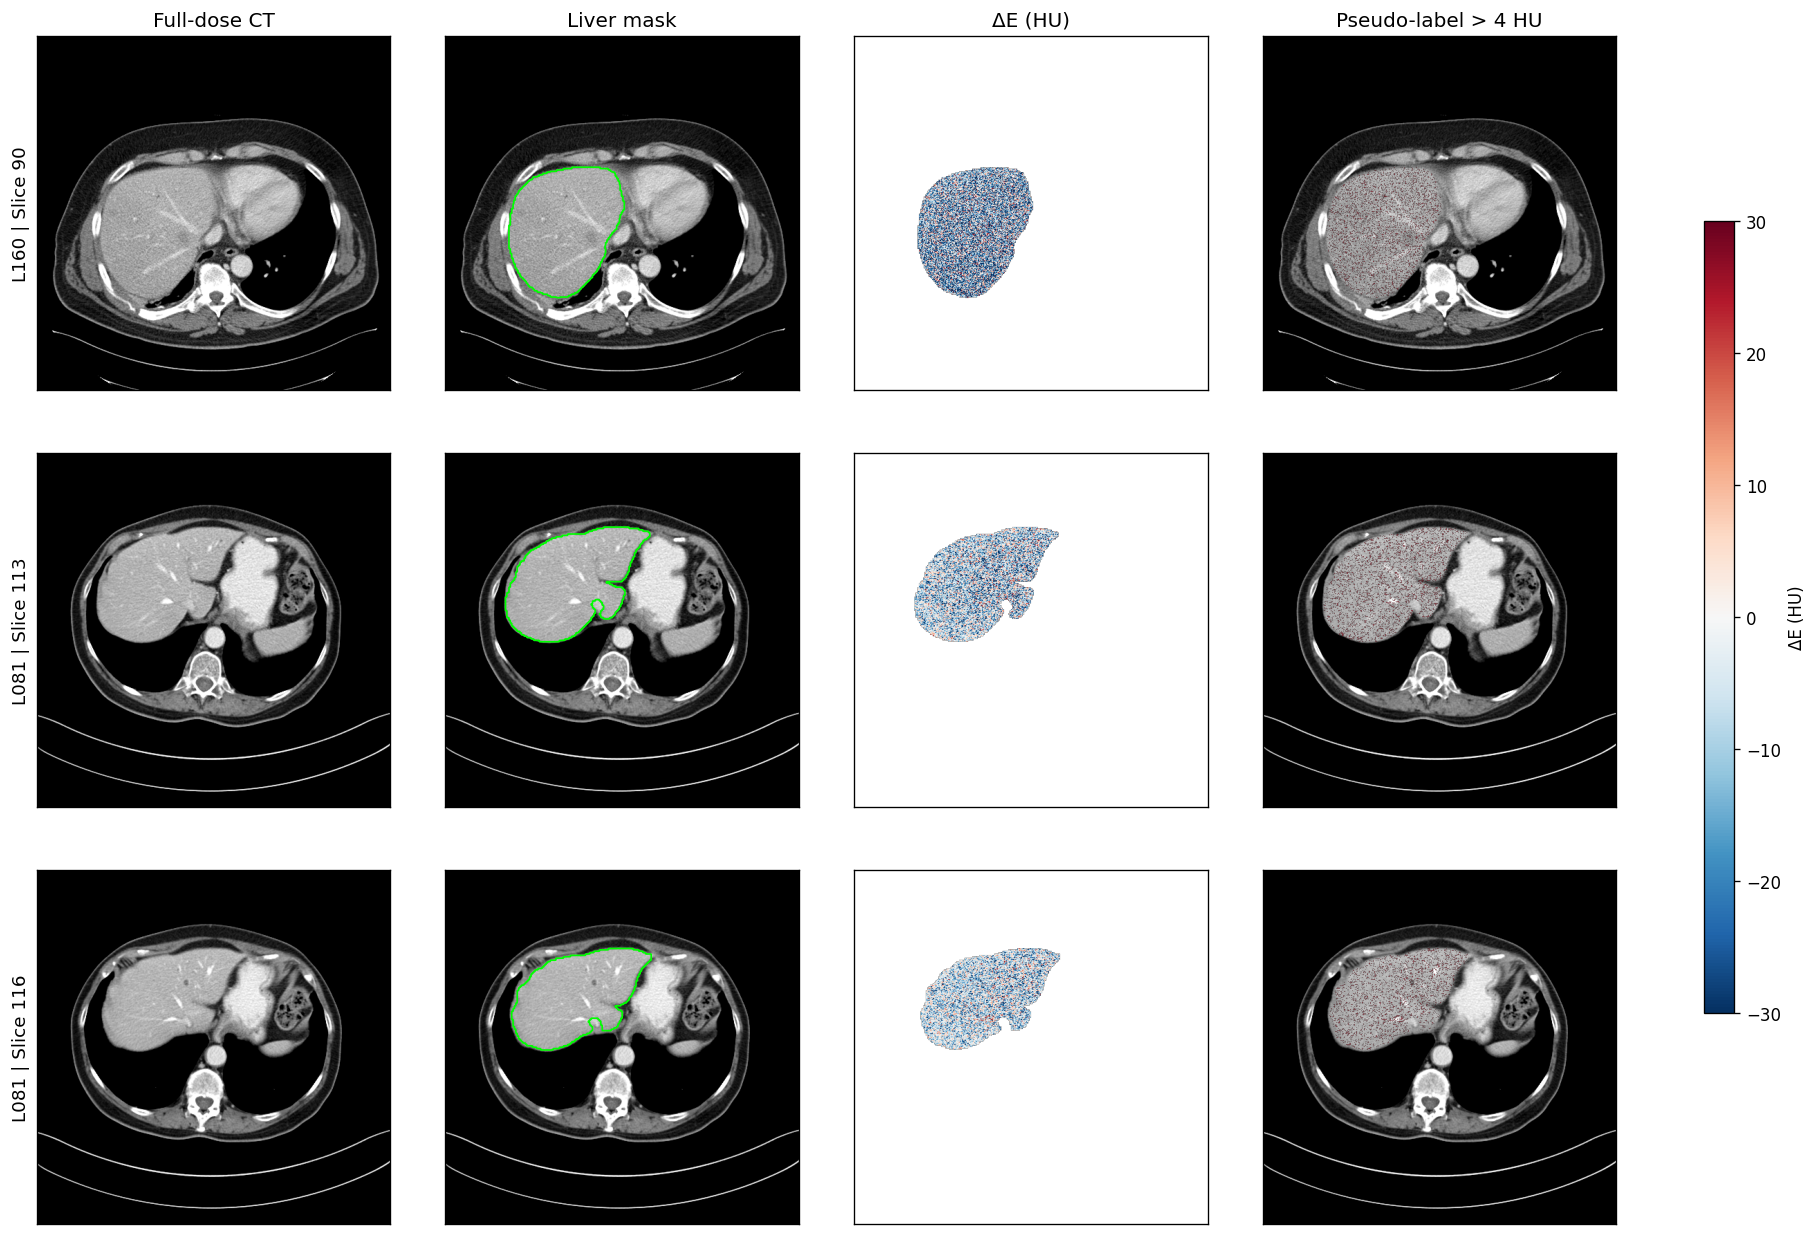

Saved: /kaggle/working/liver_error_visualization.png


In [24]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
root = Path("/kaggle/working/CAI421_processed")
qc = pd.read_csv(root / "totalseg_final/mask_qc.csv")
samples = qc.query("liver_pixels > 0").sample(3, random_state=42)
fig, ax = plt.subplots(3, 4, figsize=(17, 11), dpi=120)
titles = ["Full-dose CT", "Liver mask", "ΔE (HU)", "Pseudo-label > 4 HU"]
for j, title in enumerate(titles):
    ax[0, j].set_title(title, fontsize=12)
for r, row in enumerate(samples.itertuples()):
    case, z = row.case_id, int(row.slice)
    with np.load(root / "pairs_raw_hu" / f"{case}.npz") as f:
        low, full = f["low_hu"][z], f["full_hu"][z]
    with np.load(root / "external_redcnn_final" / f"{case}.npz") as f:
        i = np.where(f["slices"] == z)[0][0]
        den = f["denoised_hu"][i]
    with np.load(root / "totalseg_final" / f"{case}.npz") as f:
        mask = f["mask"][i].astype(bool)
    delta = np.abs(den - full) - np.abs(low - full)
    label = mask & (delta > 4)
    ax[r, 0].imshow(full, cmap="gray", vmin=-150, vmax=250)
    ax[r, 1].imshow(full, cmap="gray", vmin=-150, vmax=250)
    ax[r, 1].contour(mask, levels=[0.5], colors="lime", linewidths=1)
    im = ax[r, 2].imshow(np.ma.masked_where(~mask, delta),cmap="RdBu_r", vmin=-30, vmax=30)
    ax[r, 3].imshow(full, cmap="gray", vmin=-150, vmax=250)
    ax[r, 3].imshow(np.ma.masked_where(~label, label),cmap="Reds", alpha=0.65, vmin=0, vmax=1)
    ax[r, 0].set_ylabel(f"{case} | Slice {z}", fontsize=11)
    for a in ax[r]:
        a.set_xticks([])
        a.set_yticks([])
fig.subplots_adjust(left=0.07, right=0.85,top=0.94, bottom=0.04,wspace=0.12, hspace=0.18)
cax = fig.add_axes([0.89, 0.20, 0.015, 0.60])
fig.colorbar(im, cax=cax, label="ΔE (HU)")
out = Path("/kaggle/working/liver_error_visualization.png")
fig.savefig(out, dpi=300, bbox_inches="tight")
display(fig)
print("Saved:", out)

> We splitted the dataset on patient level not ct slices. so slice from the same patient never end up both in train and test to prevent leakage

In [26]:
root = Path("/kaggle/working/CAI421_processed")
folder = root / "alteration_labels_final"
output = folder / "five_fold_split.csv"
df = pd.read_csv(folder / "label_summary.csv")
assert len(df) == 43
assert df.case_id.nunique() == 16
assert not df.duplicated(["case_id", "slice"]).any()
# Freeze existing folds: never overwrite them
if output.exists():
    folds = pd.read_csv(output)
    print("Loaded existing frozen folds.")
else:
    df = df.sort_values(["case_id", "slice"]).reset_index(drop=True)
    cv = GroupKFold(n_splits=5, shuffle=True, random_state=42)
    df["fold"] = -1
    for fold, (_, test_idx) in enumerate(
        cv.split(df, groups=df["case_id"]), start=1):
        df.loc[test_idx, "fold"] = fold
    df.to_csv(output, index=False)
    folds = df
    print("Created and saved frozen folds.")
# Verify patient-level separation
assert len(folds) == 43
assert folds.case_id.nunique() == 16
assert folds.groupby("case_id")["fold"].nunique().eq(1).all()
assert set(folds.fold) == {1, 2, 3, 4, 5}
print("\nFold summary:")
print(folds.groupby("fold").agg(patients=("case_id", "nunique"),slices=("slice", "count"),mean_positive_percent=("altered_percent", "mean")).round(2))
print("\nSaved:", output)

Created and saved frozen folds.

Fold summary:
      patients  slices  mean_positive_percent
fold                                         
1            4      14                  17.54
2            3      10                  18.56
3            3       7                  16.76
4            3       4                  19.36
5            3       8                  16.92

Saved: /kaggle/working/CAI421_processed/alteration_labels_final/five_fold_split.csv


In [29]:
def load_cases(case_ids):
    volumes = []
    for case in case_ids:
        with (
            np.load(root / "pairs_raw_hu" / f"{case}.npz") as a,
            np.load(root / "external_redcnn_final" / f"{case}.npz") as d,
            np.load(root / "totalseg_final" / f"{case}.npz") as m,
            np.load(root / "alteration_labels_final" / f"{case}.npz") as y):
            files = [a, d, m, y]
            keys = ["low_hu", "denoised_hu", "mask", "labels"]
            selected = folds.loc[folds.case_id == case, "slice"].to_numpy()
            arrays = []
            for data, key in zip(files, keys):
                arr = data[key]
                if "slices" in data.files:
                    indices = data["slices"]
                elif "slice_indices" in data.files:
                    indices = data["slice_indices"]
                else:
                    indices = np.arange(len(arr))
                positions = {int(s): i for i, s in enumerate(indices)}
                missing = set(selected) - set(positions)
                if missing:
                    raise ValueError(f"{case}/{key}: missing slices {sorted(missing)}")
                arrays.append(arr[[positions[int(s)] for s in selected]].astype(np.float32))
            low, den, liver, label = arrays
            assert low.shape == den.shape == liver.shape == label.shape
            assert np.all(label <= liver)
            volumes.append({
                "low": (low + 1024) / 4096,
                "den": (den + 1024) / 4096,
                "mask": label,
                "lesion_mask": label,
                "valid_mask": liver})
    return volumes


In [30]:
def get_fold(fold):
    test = folds[folds.fold == fold]
    remaining = folds[folds.fold != fold]
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    tr, va = next(splitter.split(remaining, groups=remaining.case_id))
    train_ids = remaining.iloc[tr].case_id.unique()
    val_ids = remaining.iloc[va].case_id.unique()
    test_ids = test.case_id.unique()
    assert set(train_ids).isdisjoint(val_ids)
    assert set(train_ids).isdisjoint(test_ids)
    assert set(val_ids).isdisjoint(test_ids)
    return load_cases(train_ids), load_cases(val_ids), load_cases(test_ids)
train_vols, val_vols, test_vols = get_fold(1)
print(f"Train: {len(train_vols)} | Val: {len(val_vols)} | Test: {len(test_vols)}")

Train: 9 | Val: 3 | Test: 4


## RiskMapUNet architecture and training

The model, loss and crop sampler are defined below. 
The input has 3 channels: the low-dose image, the RED-CNN output, and the difference between them (scaled). RED-CNN stays frozen the whole time.

In [31]:
# RiskMapUnet, loss function and crop samples
# Model
class DoubleConv(nn.Module):
    def __init__(self, ci, co, drop=0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(ci, co, 3, padding=1, bias=False),
            nn.GroupNorm(8, co), nn.ReLU(inplace=True),
            nn.Dropout2d(drop) if drop else nn.Identity(),
            nn.Conv2d(co, co, 3, padding=1, bias=False),
            nn.GroupNorm(8, co), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.net(x)
class RiskMapUNet(nn.Module):
    def __init__(self, base=16, prior=1e-3, drop=0.1):
        super().__init__()
        c = base
        self.enc = nn.ModuleList([
            DoubleConv(3, c), DoubleConv(c, 2*c),
            DoubleConv(2*c, 4*c), DoubleConv(4*c, 8*c, drop)])
        self.bott = DoubleConv(8*c, 16*c, drop)
        self.up = nn.ModuleList([
            nn.ConvTranspose2d(16*c, 8*c, 2, 2),
            nn.ConvTranspose2d(8*c, 4*c, 2, 2),
            nn.ConvTranspose2d(4*c, 2*c, 2, 2),
            nn.ConvTranspose2d(2*c, c, 2, 2)])
        self.dec = nn.ModuleList([
            DoubleConv(16*c, 8*c), DoubleConv(8*c, 4*c),
            DoubleConv(4*c, 2*c), DoubleConv(2*c, c)])
        self.head = nn.Conv2d(c, 1, 1)
        self.set_prior(prior)
    def set_prior(self, p):
        p = float(np.clip(p, 1e-6, 1-1e-6))
        nn.init.zeros_(self.head.weight)
        nn.init.constant_(self.head.bias, math.log(p/(1-p)))
    def forward(self, x):
        h, w = x.shape[-2:]
        ph, pw = (-h) % 16, (-w) % 16
        if ph or pw:
            mode = "reflect" if h > ph and w > pw else "replicate"
            x = F.pad(x, (0, pw, 0, ph), mode=mode)
        skips = []
        for enc in self.enc:
            x = enc(x)
            skips.append(x)
            x = F.max_pool2d(x, 2)
        x = self.bott(x)
        for up, dec, skip in zip(self.up, self.dec, reversed(skips)):
            x = dec(torch.cat([up(x), skip], 1))
        return self.head(x)[..., :h, :w]
    @torch.no_grad()
    def predict(self, x):
        was_training = self.training
        self.eval()
        p = torch.sigmoid(self(x))
        self.train(was_training)
        return p
def make_input(low, den, scale=10.0):
    return torch.stack([low, den, (den-low)*scale], dim=1)

In [32]:
class AlterationLoss(nn.Module):
    def __init__(self, pos_weight=20, alpha=.3, beta=.7,
                 gamma=.75, tv_weight=.5):
        super().__init__()
        self.pw, self.a, self.b = pos_weight, alpha, beta
        self.g, self.tw = gamma, tv_weight
    def forward(self, logits, target, valid=None):
        target = target.float()
        valid = torch.ones_like(target) if valid is None else valid.float()
        if valid.sum() == 0:
            return logits.sum() * 0
        pw = torch.as_tensor(self.pw, device=logits.device, dtype=logits.dtype)
        bce = F.binary_cross_entropy_with_logits(logits, target, pos_weight=pw, reduction="none")
        bce = (bce * valid).sum() / valid.sum()
        p, y = torch.sigmoid(logits)*valid, target*valid
        if y.sum() == 0:
            return bce
        tp = (p*y).sum()
        fp = (p*(1-y)).sum()
        fn = ((1-p)*y).sum()
        tv = 1 - (tp+1e-6)/(tp+self.a*fp+self.b*fn+1e-6)
        return bce + self.tw*tv.pow(self.g)

In [33]:
class CropSampler:
    #Each volume: low, den, mask, lesion_mask, optional valid_mask.
    def __init__(self, volumes, crop=128, seed=0, augment=True):
        self.vols, self.crop, self.augment = volumes, crop, augment
        self.rng = np.random.default_rng(seed)
        self.pos = [np.argwhere(v["mask"] > 0) for v in volumes]
        self.les = [np.argwhere(v["lesion_mask"] > 0) for v in volumes]
        self.pos_ids = [i for i, a in enumerate(self.pos) if len(a)]
        self.les_ids = [i for i, a in enumerate(self.les) if len(a)]
        for v in volumes:
            assert v["mask"].shape[1] >= crop and v["mask"].shape[2] >= crop
    def one(self):
        r, c = self.rng, self.crop
        mode = r.choice(3, p=[.4, .4, .2])
        ids = self.pos_ids if mode == 0 else self.les_ids if mode == 1 else []
        coords = self.pos if mode == 0 else self.les
        if ids:
            i = int(r.choice(ids))
            z, y, x = coords[i][r.integers(len(coords[i]))]
            y += r.integers(-c//3, c//3+1)
            x += r.integers(-c//3, c//3+1)
        else:
            i = int(r.integers(len(self.vols)))
            Z, H, W = self.vols[i]["mask"].shape
            z, y, x = r.integers(Z), r.integers(H), r.integers(W)
        v = self.vols[i]
        _, H, W = v["mask"].shape
        y0 = int(np.clip(y-c//2, 0, H-c))
        x0 = int(np.clip(x-c//2, 0, W-c))
        sl = (int(z), slice(y0, y0+c), slice(x0, x0+c))
        keys = ["low", "den", "mask"]
        a = [np.asarray(v[k][sl], dtype=np.float32) for k in keys]
        valid = v.get("valid_mask")
        a.append(np.asarray(valid[sl], dtype=np.float32)
                 if valid is not None else np.ones((c, c), np.float32))
        if self.augment:
            if r.random() < .5: a = [q[:, ::-1] for q in a]
            if r.random() < .5: a = [q[::-1] for q in a]
            k = int(r.integers(4))
            a = [np.rot90(q, k) for q in a]
        return [np.ascontiguousarray(q) for q in a]
    def batch(self, n=8, device="cpu"):
        L, D, Y, V = zip(*(self.one() for _ in range(n)))
        t = lambda a: torch.from_numpy(np.stack(a)).to(device)
        return make_input(t(L), t(D)), t(Y)[:, None], t(V)[:, None]
    def positive_rate(self, n=200):
        return float(np.mean([self.one()[2].mean() for _ in range(n)]))

In [34]:
@torch.no_grad()
def metrics(logits, target, threshold=.5, valid=None):
    p = torch.sigmoid(logits) >= threshold
    y = target.bool()
    v = torch.ones_like(y) if valid is None else valid.bool()
    tp = (p & y & v).sum().item()
    fp = (p & ~y & v).sum().item()
    fn = (~p & y & v).sum().item()
    eps = 1e-8
    return {
        "dice": 2*tp/(2*tp+fp+fn+eps),
        "iou": tp/(tp+fp+fn+eps),
        "precision": tp/(tp+fp+eps),
        "recall": tp/(tp+fn+eps),
        "tp": tp, "fp": fp, "fn": fn
    }

In [35]:
device = "cuda" if torch.cuda.is_available() else "cpu"
net = RiskMapUNet().to(device)
x = torch.randn(1, 3, 128, 128, device=device)
y = torch.zeros(1, 1, 128, 128, device=device)
y[:, :, 60:68, 60:68] = 1
logits = net(x)
loss = AlterationLoss()(logits, y)
loss.backward()
print("Device:", device)
print("Parameters:", f"{sum(p.numel() for p in net.parameters()):,}")
print("Output shape:", tuple(logits.shape))
print("Loss:", round(loss.item(), 4))
print("Backward pass:", "OK")

Device: cuda
Parameters: 1,942,577
Output shape: (1, 1, 128, 128)
Loss: 1.0402
Backward pass: OK


**TRAINING**

In [36]:
@torch.no_grad()
def validate(model, volumes, criterion):
    model.eval()
    total, count = 0., 0
    for v in volumes:
        for i in range(len(v["low"])):
            low = torch.from_numpy(v["low"][i:i+1]).to(device)
            den = torch.from_numpy(v["den"][i:i+1]).to(device)
            y = torch.from_numpy(v["mask"][i:i+1, None]).to(device)
            liver = torch.from_numpy(v["valid_mask"][i:i+1, None]).to(device)
            loss = criterion(model(make_input(low, den)), y, liver)
            total += loss.item()
            count += 1
    return total / count

Results after training and validation:

- Fold 1: best validation loss 2.3603
- Fold 2: best validation loss 2.4154
- Fold 3: best validation loss 2.4539
- Fold 4: best validation loss 2.4501
- Fold 5: best validation loss 2.4235


In [37]:
save_dir = Path("/kaggle/working/RiskMapUNet_v2_final")
save_dir.mkdir(exist_ok=True)
for fold in range(1, 6):
    train_vols, val_vols, _ = get_fold(fold)
    torch.manual_seed(42 + fold)
    model = RiskMapUNet().to(device)
    loss_fn = AlterationLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)
    sampler = CropSampler(train_vols, crop=128, seed=42 + fold)
    best, patience = float("inf"), 0
    for epoch in range(1, 101):
        model.train()
        losses = []
        for _ in range(50):
            x, y, liver = sampler.batch(4, device)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(x), y, liver)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        val = validate(model, val_vols, loss_fn)
        if val < best - 1e-4:
            best, patience = val, 0
            torch.save(model.state_dict(), save_dir / f"fold_{fold}.pt")
        else:
            patience += 1
        if epoch == 1 or epoch % 5 == 0:
            print(f"Fold {fold} | Epoch {epoch} | "
                  f"Train {np.mean(losses):.4f} | Val {val:.4f}")
        if patience >= 12:
            break
    print(f"Fold {fold} complete | Best validation loss: {best:.4f}")

Fold 1 | Epoch 1 | Train 25.6237 | Val 24.6285
Fold 1 | Epoch 5 | Train 24.3280 | Val 22.1617
Fold 1 | Epoch 10 | Train 22.6188 | Val 18.1884
Fold 1 | Epoch 15 | Train 20.3048 | Val 13.6104
Fold 1 | Epoch 20 | Train 17.9360 | Val 9.0710
Fold 1 | Epoch 25 | Train 15.3936 | Val 6.5205
Fold 1 | Epoch 30 | Train 12.4156 | Val 3.5319
Fold 1 | Epoch 35 | Train 10.8338 | Val 2.8877
Fold 1 | Epoch 40 | Train 8.8343 | Val 2.9760
Fold 1 | Epoch 45 | Train 7.2169 | Val 2.5132
Fold 1 | Epoch 50 | Train 6.0069 | Val 2.5655
Fold 1 | Epoch 55 | Train 4.7704 | Val 2.4420
Fold 1 | Epoch 60 | Train 4.3001 | Val 2.3892
Fold 1 | Epoch 65 | Train 3.6476 | Val 2.3865
Fold 1 | Epoch 70 | Train 3.4738 | Val 2.4503
Fold 1 | Epoch 75 | Train 3.1066 | Val 2.3790
Fold 1 | Epoch 80 | Train 2.9068 | Val 2.3863
Fold 1 | Epoch 85 | Train 2.6903 | Val 2.3926
Fold 1 | Epoch 90 | Train 2.5877 | Val 2.3739
Fold 1 | Epoch 95 | Train 2.5573 | Val 2.3589
Fold 1 | Epoch 100 | Train 2.5176 | Val 2.3696
Fold 1 complete | Best 

**Testing**

Here we test how well RiskMapUNet finds the alterations in patients it has not seen. The recall is very high (99.49%) but the precision is low (18.43%), so the model gives a lot of false positives.


In [38]:
results = []
for fold in range(1, 6):
    _, _, test_vols = get_fold(fold)
    model = RiskMapUNet().to(device)
    model.load_state_dict(torch.load(save_dir / f"fold_{fold}.pt",map_location=device,weights_only=True))
    model.eval()
    tp = fp = fn = 0
    targets, probabilities = [], []
    with torch.no_grad():
        for v in test_vols:
            for i in range(len(v["low"])):
                low = torch.from_numpy(v["low"][i:i+1]).to(device)
                den = torch.from_numpy(v["den"][i:i+1]).to(device)
                prob = model.predict(make_input(low, den))[0, 0].cpu().numpy()
                liver = v["valid_mask"][i].astype(bool)
                y = v["mask"][i][liver].astype(bool)
                p = prob[liver]
                pred = p >= 0.5
                tp += np.sum(pred & y)
                fp += np.sum(pred & ~y)
                fn += np.sum(~pred & y)
                targets.append(y)
                probabilities.append(p)
    y = np.concatenate(targets)
    p = np.concatenate(probabilities)
    results.append({"fold": fold,"dice": 2*tp / (2*tp + fp + fn + 1e-8),"iou": tp / (tp + fp + fn + 1e-8),"precision": tp / (tp + fp + 1e-8),"recall": tp / (tp + fn + 1e-8),"auprc": average_precision_score(y, p)})
results = pd.DataFrame(results)
print(results.round(4))
print("\nMean ± SD")
print(results.drop(columns="fold").agg(["mean", "std"]).round(4))
results.to_csv(save_dir / "five_fold_results.csv", index=False)

   fold    dice     iou  precision  recall   auprc
0     1  0.3081  0.1821     0.1822  0.9955  0.2353
1     2  0.3211  0.1912     0.1914  0.9953  0.2116
2     3  0.2993  0.1760     0.1761  0.9951  0.2029
3     4  0.3315  0.1987     0.1988  0.9973  0.2551
4     5  0.2951  0.1731     0.1735  0.9852  0.1908

Mean ± SD
        dice     iou  precision  recall   auprc
mean  0.3110  0.1842     0.1844  0.9937  0.2191
std   0.0152  0.0107     0.0106  0.0048  0.0259


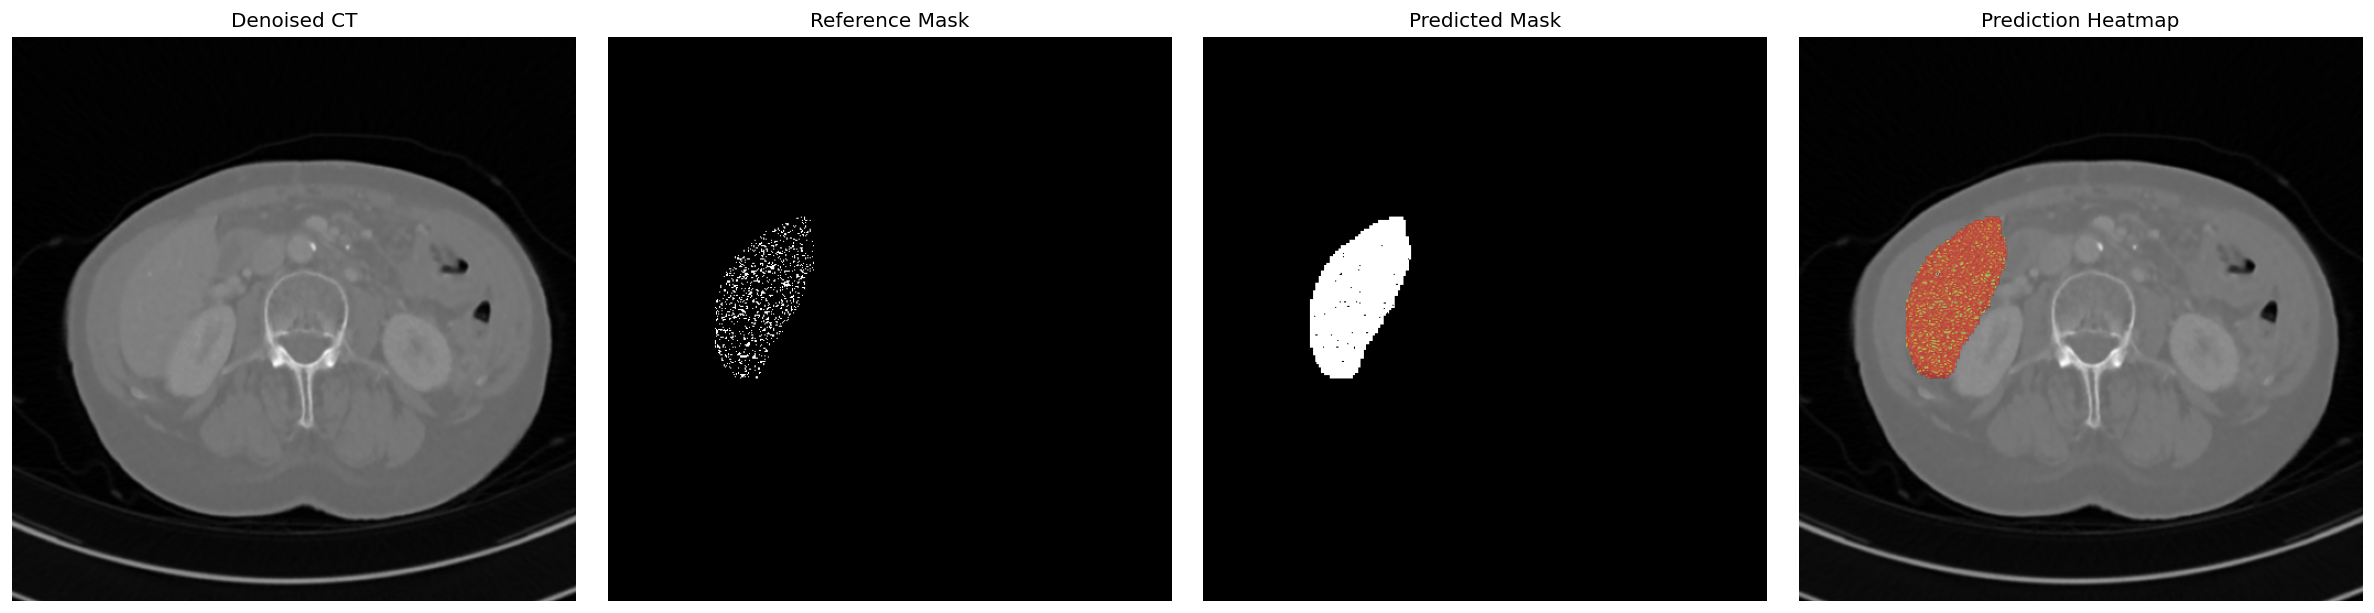

In [39]:
item = val_vols[0]
s = 0  # Slice index: 0–3
def to_np(x):
    return x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)
low = torch.as_tensor(item["low"][s:s+1], dtype=torch.float32, device=device)
den = torch.as_tensor(item["den"][s:s+1], dtype=torch.float32, device=device)
model.eval()
with torch.no_grad():
    logits = model(make_input(low, den))
    probability = torch.sigmoid(logits)[0, 0].cpu().numpy()
den = to_np(item["den"][s])
truth = to_np(item["lesion_mask"][s])
liver = to_np(item["valid_mask"][s])
prediction = (probability >= 0.5) & (liver > 0)
fig, axes = plt.subplots(1, 4, figsize=(20, 5), dpi=120)
for ax, img, title in zip(axes[:3],[den, truth, prediction],["Denoised CT", "Reference Mask", "Predicted Mask"]):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
axes[3].imshow(den, cmap="gray")
axes[3].imshow(np.ma.masked_where(liver == 0, probability),cmap="jet", alpha=0.5, vmin=0, vmax=1)
axes[3].set_title("Prediction Heatmap")
axes[3].axis("off")
fig.tight_layout()
display(fig)
plt.close(fig)

saving result for later use

In [41]:
from pathlib import Path
import numpy as np
import torch

out = Path("/kaggle/working/test_examples")
out.mkdir(parents=True, exist_ok=True)

def to_np(x):
    return x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)

file = out / "fold1_test_example.npz"

np.savez_compressed(
    file,
    low=to_np(low),
    den=to_np(den),
    truth=to_np(truth),
    prediction=to_np(prediction),
    liver=to_np(liver),
    probability=to_np(probability)
)

print("Saved:", file)

Saved: /kaggle/working/test_examples/fold1_test_example.npz


# Baseline 1: Attention U-Net

In [42]:
#Reuse existing imports, root, and fold definitions
BASE_OUT = Path("/kaggle/working/CAI421_results/baseline_attention_unet")
BASE_OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
CROP_SIZE = 256
BATCH_SIZE = 4
EPOCHS = 20
SAMPLES_PER_EPOCH = 64
LEARNING_RATE = 1e-4
BASE_CHANNELS = 16
PATIENCE = 6
THRESHOLD = 0.50
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Reuse the existing processed dataset
BASE_RAW = root / "pairs_raw_hu"
BASE_RED = root / "external_redcnn_final"
BASE_LIVER = root / "totalseg_final"
BASE_LABELS = root / "alteration_labels_final"

In [43]:
# Use the same frozen five-fold split
fold_df = folds.copy()
assert len(fold_df) == 43, "Expected 43 finalized approved slices"
assert fold_df.case_id.nunique() == 16
assert fold_df.groupby("case_id").fold.nunique().eq(1).all()
assert set(fold_df.fold.unique()) == {1, 2, 3, 4, 5}
assert not fold_df.duplicated(["case_id", "slice"]).any()
print("Device:", DEVICE)
print("Patients:", fold_df.case_id.nunique())
print("Slices:", len(fold_df))
display(fold_df.groupby("fold").agg(patients=("case_id", "nunique"),slices=("slice", "count")))


Device: cuda
Patients: 16
Slices: 43


,patients,slices
fold,,
1,4,14
2,3,10
3,3,7
4,3,4
5,3,8


In [44]:
# 3. Aligned slice loading and input preparation
records = []
for row in fold_df.sort_values(["case_id", "slice"]).itertuples(index=False):
    case_id = str(row.case_id)
    slice_id = int(row.slice)
    fold = int(row.fold)
    # Low-dose CT
    with np.load(BASE_RAW / f"{case_id}.npz", allow_pickle=False) as data:
        low_hu = data["low_hu"][slice_id].astype(np.float32)
    # Match each processed output to its original slice index
    def load_aligned_slice(folder, key):
        with np.load(folder / f"{case_id}.npz", allow_pickle=False) as data:
            positions = np.where(data["slices"].astype(int) == slice_id)[0]
            if len(positions) != 1:
                raise ValueError(
                    f"{case_id}, slice {slice_id}: {key} alignment failed"
                )
            return data[key][int(positions[0])].copy()
    den_hu = load_aligned_slice(BASE_RED, "denoised_hu").astype(np.float32)
    liver = load_aligned_slice(BASE_LIVER, "mask").astype(np.uint8)
    target = load_aligned_slice(BASE_LABELS, "labels").astype(np.uint8)
    # Verify image dimensions and liver-label consistency
    if not (low_hu.shape == den_hu.shape == liver.shape == target.shape):
        raise ValueError(f"Shape mismatch: {case_id}, slice {slice_id}")
    if low_hu.shape != (512, 512):
        raise ValueError(f"Unexpected image size: {case_id}, slice {slice_id}")
    if liver.sum() == 0:
        raise ValueError(f"Empty liver mask: {case_id}, slice {slice_id}")
    if np.any((target > 0) & (liver == 0)):
        raise ValueError(f"Alteration labels outside liver: {case_id}, slice {slice_id}")
    # Original baseline HU window
    low = np.clip((low_hu + 160.0) / 400.0, 0, 1)
    den = np.clip((den_hu + 160.0) / 400.0, 0, 1)
    # Three-channel Attention U-Net input
    x = np.stack([low, den, (den - low) * 10.0],axis=0).astype(np.float32)
    records.append({"case_id": case_id,"slice": slice_id,"fold": fold,"x": x,"y": target.astype(np.float32),"valid": liver.astype(np.float32)})
print(f"Loaded {len(records)} aligned slices from "
    f"{len(set(r['case_id'] for r in records))} patients.")
positive_fraction = (sum(r["y"].sum() for r in records) /max(1, sum(r["valid"].sum() for r in records)))
print("Mean positive-pixel fraction inside liver:", round(positive_fraction, 4))

Loaded 43 aligned slices from 16 patients.
Mean positive-pixel fraction inside liver: 0.1787


In [45]:
class LiverPatchDataset(Dataset):
    def __init__(self, items, samples, crop=256, augment=True, seed=42):
        self.items = items
        self.samples = samples
        self.crop = crop
        self.augment = augment
        self.rng = np.random.default_rng(seed)
        # Identify eligible sampling locations within the liver
        self.coords = [np.argwhere(item["valid"] > 0) for item in items]
        if any(len(coords) == 0 for coords in self.coords):
            raise ValueError("A training slice contains an empty liver mask.")
    def __len__(self):
        return self.samples
    def __getitem__(self, index):
        item_id = int(self.rng.integers(len(self.items)))
        item = self.items[item_id]
        center = self.coords[item_id][self.rng.integers(len(self.coords[item_id]))]
        cy, cx = map(int, center)
        # Extract a fixed-size patch within image boundaries
        half = self.crop // 2
        y0 = int(np.clip(cy - half, 0, 512 - self.crop))
        x0 = int(np.clip(cx - half, 0, 512 - self.crop))
        region = (slice(y0, y0 + self.crop),slice(x0, x0 + self.crop))
        x = item["x"][:, region[0], region[1]].copy()
        y = item["y"][region].copy()
        valid = item["valid"][region].copy()
        # Apply identical spatial transformations to all three arrays
        if self.augment:
            if self.rng.random() < 0.5:
                x = x[:, :, ::-1]
                y = y[:, ::-1]
                valid = valid[:, ::-1]
            if self.rng.random() < 0.5:
                x = x[:, ::-1, :]
                y = y[::-1, :]
                valid = valid[::-1, :]
            k = int(self.rng.integers(4))
            x = np.rot90(x, k, axes=(1, 2))
            y = np.rot90(y, k)
            valid = np.rot90(valid, k)
        return (torch.from_numpy(np.ascontiguousarray(x)).float(),torch.from_numpy(np.ascontiguousarray(y[None])).float(),torch.from_numpy(np.ascontiguousarray(valid[None])).float())

In [46]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        groups = 8 if out_ch % 8 == 0 else 1
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)
class AttentionGate(nn.Module):
    def __init__(self, gate_ch, skip_ch, inter_ch):
        super().__init__()
        self.gate_proj = nn.Sequential(
            nn.Conv2d(gate_ch, inter_ch, kernel_size=1, bias=True),
            nn.GroupNorm(1, inter_ch)
        )
        self.skip_proj = nn.Sequential(
            nn.Conv2d(skip_ch, inter_ch, kernel_size=1, bias=True),
            nn.GroupNorm(1, inter_ch)
        )
        self.score = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.Conv2d(inter_ch, 1, kernel_size=1),
            nn.Sigmoid()
        )
    def forward(self, gate, skip):
        # Align spatial dimensions before attention weighting
        if gate.shape[-2:] != skip.shape[-2:]:
            gate = F.interpolate(gate,size=skip.shape[-2:],mode="bilinear",align_corners=False)
        attention = self.score(self.gate_proj(gate) + self.skip_proj(skip))
        return skip * attention
class AttentionUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, base=16):
        super().__init__()
        b = base
        self.pool = nn.MaxPool2d(kernel_size=2)
        # Encoder
        self.enc1 = ConvBlock(in_channels, b)
        self.enc2 = ConvBlock(b, 2 * b)
        self.enc3 = ConvBlock(2 * b, 4 * b)
        self.enc4 = ConvBlock(4 * b, 8 * b)
        # Bottleneck
        self.bottleneck = ConvBlock(8 * b, 16 * b)
        # Decoder with attention-gated skip connections
        self.up4 = nn.ConvTranspose2d(16 * b, 8 * b, 2, stride=2)
        self.att4 = AttentionGate(8 * b, 8 * b, 4 * b)
        self.dec4 = ConvBlock(16 * b, 8 * b)
        self.up3 = nn.ConvTranspose2d(8 * b, 4 * b, 2, stride=2)
        self.att3 = AttentionGate(4 * b, 4 * b, 2 * b)
        self.dec3 = ConvBlock(8 * b, 4 * b)
        self.up2 = nn.ConvTranspose2d(4 * b, 2 * b, 2, stride=2)
        self.att2 = AttentionGate(2 * b, 2 * b, b)
        self.dec2 = ConvBlock(4 * b, 2 * b)
        self.up1 = nn.ConvTranspose2d(2 * b, b, 2, stride=2)
        self.att1 = AttentionGate(b, b, max(1, b // 2))
        self.dec1 = ConvBlock(2 * b, b)
        # Single-channel segmentation output
        self.head = nn.Conv2d(b, out_channels, kernel_size=1)
    def forward(self, x):
        height, width = x.shape[-2:]
        # Pad dimensions to support four downsampling stages
        pad_h = (-height) % 16
        pad_w = (-width) % 16
        if pad_h or pad_w:
            x = F.pad(x,(0, pad_w, 0, pad_h),mode="replicate")
        # Encoding
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        bottleneck = self.bottleneck(self.pool(e4))
        # Attention-guided decoding
        d4 = self.up4(bottleneck)
        d4 = self.dec4(torch.cat([d4, self.att4(d4, e4)], dim=1))
        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, self.att3(d3, e3)], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, self.att2(d2, e2)], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, self.att1(d1, e1)], dim=1))
        # Restore original spatial dimensions
        return self.head(d1)[..., :height, :width]

In [47]:
class MaskedBCEDiceLoss(nn.Module):
    def __init__(self, pos_weight=3.0, dice_weight=1.0):
        super().__init__()
        self.register_buffer(
            "pos_weight",
            torch.tensor(float(pos_weight))
        )
        self.dice_weight = dice_weight
    def forward(self, logits, target, valid):
        # Weighted binary cross-entropy within the liver
        bce_map = F.binary_cross_entropy_with_logits(
            logits,
            target,
            reduction="none",
            pos_weight=self.pos_weight
        )
        bce = ((bce_map * valid).sum() /valid.sum().clamp_min(1.0))
        # Soft Dice loss within the same region
        probabilities = torch.sigmoid(logits) * valid
        target = target * valid
        dims = (1, 2, 3)
        intersection = (probabilities * target).sum(dims)
        denominator = probabilities.sum(dims) + target.sum(dims)
        dice = ((2 * intersection + 1e-6) /(denominator + 1e-6))
        dice_loss = 1 - dice.mean()
        return bce + self.dice_weight * dice_loss
@torch.no_grad()
def evaluate_attention_model(model, items):
    model.eval()
    tp = fp = fn = 0
    losses = []
    criterion = MaskedBCEDiceLoss().to(DEVICE)
    for item in items:
        # Prepare full-resolution inputs and masks
        x = torch.from_numpy(
            item["x"][None]
        ).float().to(DEVICE)
        y = torch.from_numpy(
            item["y"][None, None]
        ).float().to(DEVICE)
        valid = torch.from_numpy(
            item["valid"][None, None]
        ).float().to(DEVICE)
        # Generate predictions and calculate masked loss
        logits = model(x)
        losses.append(float(criterion(logits, y, valid).item()))
        # Apply the fixed threshold within the liver
        prediction = ((torch.sigmoid(logits) >= THRESHOLD) &(valid > 0))
        reference = (y > 0.5) & (valid > 0)
        # Accumulate pixel-level confusion counts
        tp += int((prediction & reference).sum().item())
        fp += int((prediction & ~reference & (valid > 0)) .sum().item())
        fn += int((~prediction & reference).sum().item())
        del x, y, valid, logits
    # Compute aggregate segmentation metrics
    eps = 1e-8
    return {
        "loss": float(np.mean(losses)),
        "dice": 2 * tp / (2 * tp + fp + fn + eps),
        "iou": tp / (tp + fp + fn + eps),
        "precision": tp / (tp + fp + eps),
        "recall": tp / (tp + fn + eps),
        "tp": tp,
        "fp": fp,
        "fn": fn
    }

In [48]:
# Set reproducible random seeds for each fold
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
# Each fold is held out once for validation. No patient appears in both sets.
fold_results = []
for held_out_fold in range(1, 6):
    print(f"\n{'='*18} FOLD {held_out_fold}/5 {'='*18}")
    train_items = [r for r in records if r["fold"] != held_out_fold]
    val_items = [r for r in records if r["fold"] == held_out_fold]
    train_patients = {r["case_id"] for r in train_items}
    val_patients = {r["case_id"] for r in val_items}
    assert train_patients.isdisjoint(val_patients)
    print("Train patients:", len(train_patients), "| validation patients:", len(val_patients))
    print("Train slices:", len(train_items), "| validation slices:", len(val_items))
    set_seed(SEED + held_out_fold)
    train_ds = LiverPatchDataset(train_items, samples=SAMPLES_PER_EPOCH, crop=CROP_SIZE,augment=True, seed=SEED + held_out_fold)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False,num_workers=0, pin_memory=(DEVICE.type == "cuda"))
    model = AttentionUNet(base=BASE_CHANNELS).to(DEVICE)
    criterion = MaskedBCEDiceLoss(pos_weight=3.0, dice_weight=1.0).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
    best_dice = -1.0
    best_epoch = 0
    bad_epochs = 0
    best_path = BASE_OUT / f"attention_unet_fold_{held_out_fold}_best.pt"
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_losses = []
        for x, y, valid in train_loader:
            x = x.to(DEVICE, non_blocking=True)
            y = y.to(DEVICE, non_blocking=True)
            valid = valid.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y, valid)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_losses.append(float(loss.item()))
        val_metrics = evaluate_attention_model(model, val_items)
        scheduler.step(val_metrics["dice"])
        print(
            f"Fold {held_out_fold} | Epoch {epoch:02d}/{EPOCHS} "
            f"| train_loss={np.mean(train_losses):.4f} "
            f"| val_dice={val_metrics['dice']:.4f} "
            f"| val_iou={val_metrics['iou']:.4f}"
        )
        if val_metrics["dice"] > best_dice:
            best_dice = val_metrics["dice"]
            best_epoch = epoch
            bad_epochs = 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "fold": held_out_fold,
                "epoch": epoch,
                "validation_metrics": val_metrics,
                "threshold": THRESHOLD,
                "input_channels": ["low_dose", "external_redcnn", "difference_x10"]}, best_path)
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print("Early stopping.")
                break
    # Reload the best checkpoint and record held-out fold metrics.
    checkpoint = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    final_metrics = evaluate_attention_model(model, val_items)
    final_metrics.update({
        "fold": held_out_fold,
        "best_epoch": best_epoch,
        "train_patients": len(train_patients),
        "validation_patients": len(val_patients),
        "train_slices": len(train_items),
        "validation_slices": len(val_items),
        "checkpoint": str(best_path)})
    fold_results.append(final_metrics)
    print("Best fold result:", final_metrics)
    del model, optimizer, criterion, train_loader, train_ds
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()



================== FOLD 1/5 ==================
Train patients: 12 | validation patients: 4
Train slices: 29 | validation slices: 14
Fold 1 | Epoch 01/20 | train_loss=1.6888 | val_dice=0.0584 | val_iou=0.0301
Fold 1 | Epoch 02/20 | train_loss=1.6631 | val_dice=0.0447 | val_iou=0.0229
Fold 1 | Epoch 03/20 | train_loss=1.6575 | val_dice=0.0198 | val_iou=0.0100
Fold 1 | Epoch 04/20 | train_loss=1.6493 | val_dice=0.0175 | val_iou=0.0088
Fold 1 | Epoch 05/20 | train_loss=1.6487 | val_dice=0.0279 | val_iou=0.0141
Fold 1 | Epoch 06/20 | train_loss=1.6500 | val_dice=0.0352 | val_iou=0.0179
Fold 1 | Epoch 07/20 | train_loss=1.6381 | val_dice=0.0447 | val_iou=0.0228
Early stopping.
Best fold result: {'loss': 1.6673664365495955, 'dice': 0.058371459414992756, 'iou': 0.030063144517542783, 'precision': 0.18913966852653522, 'recall': 0.0345110553909225, 'tp': 2271, 'fp': 9736, 'fn': 63534, 'fold': 1, 'best_epoch': 1, 'train_patients': 12, 'validation_patients': 4, 'train_slices': 29, 'validation_slic

In [49]:
metric_cols = ["dice", "iou", "precision", "recall", "auprc"]
for result in fold_results:
    fold = result["fold"]
    items = [r for r in records if r["fold"] == fold]
    checkpoint = torch.load(result["checkpoint"], map_location=DEVICE, weights_only=False)
    model = AttentionUNet().to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    probs, labels = [], []
    with torch.no_grad():
        for item in items:
            x = torch.as_tensor(item["x"][None], dtype=torch.float32, device=DEVICE)
            y = np.asarray(item["y"])
            valid = np.asarray(item["valid"]) > 0
            p = torch.sigmoid(model(x))[0, 0].cpu().numpy()
            probs.append(p[valid].ravel())
            labels.append(y[valid].ravel())
    probs, labels = np.concatenate(probs), np.concatenate(labels)
    result["auprc"] = (float(average_precision_score(labels, probs)) if np.any(labels) else np.nan)
    print(f"Fold {fold}: AUPRC = {result['auprc']:.4f}")
    del model
results_df = pd.DataFrame(fold_results)
summary = results_df[metric_cols].agg(["mean", "std"]).round(4)
results_path = BASE_OUT / "attention_unet_5fold_metrics.csv"
summary_path = BASE_OUT / "attention_unet_5fold_summary.csv"
results_df.to_csv(results_path, index=False)
summary.to_csv(summary_path)
print("\nATTENTION U-NET — FIVE-FOLD RESULTS")
display(results_df[["fold", "best_epoch", *metric_cols]].round(4))
display(summary)
print("Saved:", results_path, summary_path)

Fold 1: AUPRC = 0.1848
Fold 2: AUPRC = 0.2268
Fold 3: AUPRC = 0.1998
Fold 4: AUPRC = 0.2000
Fold 5: AUPRC = 0.1937

ATTENTION U-NET — FIVE-FOLD RESULTS


,fold,best_epoch,dice,iou,precision,recall,auprc
0,1,1,0.0584,0.0301,0.1891,0.0345,0.1848
1,2,19,0.2869,0.1675,0.2305,0.3799,0.2268
2,3,19,0.2234,0.1257,0.2034,0.2477,0.1998
3,4,1,0.0833,0.0434,0.2006,0.0525,0.2000
4,5,18,0.2250,0.1267,0.1972,0.2619,0.1937


,dice,iou,precision,recall,auprc
mean,0.1754,0.0987,0.2042,0.1953,0.2010
std,0.0992,0.0592,0.0156,0.1479,0.0157


Saved: /kaggle/working/CAI421_results/baseline_attention_unet/attention_unet_5fold_metrics.csv /kaggle/working/CAI421_results/baseline_attention_unet/attention_unet_5fold_summary.csv


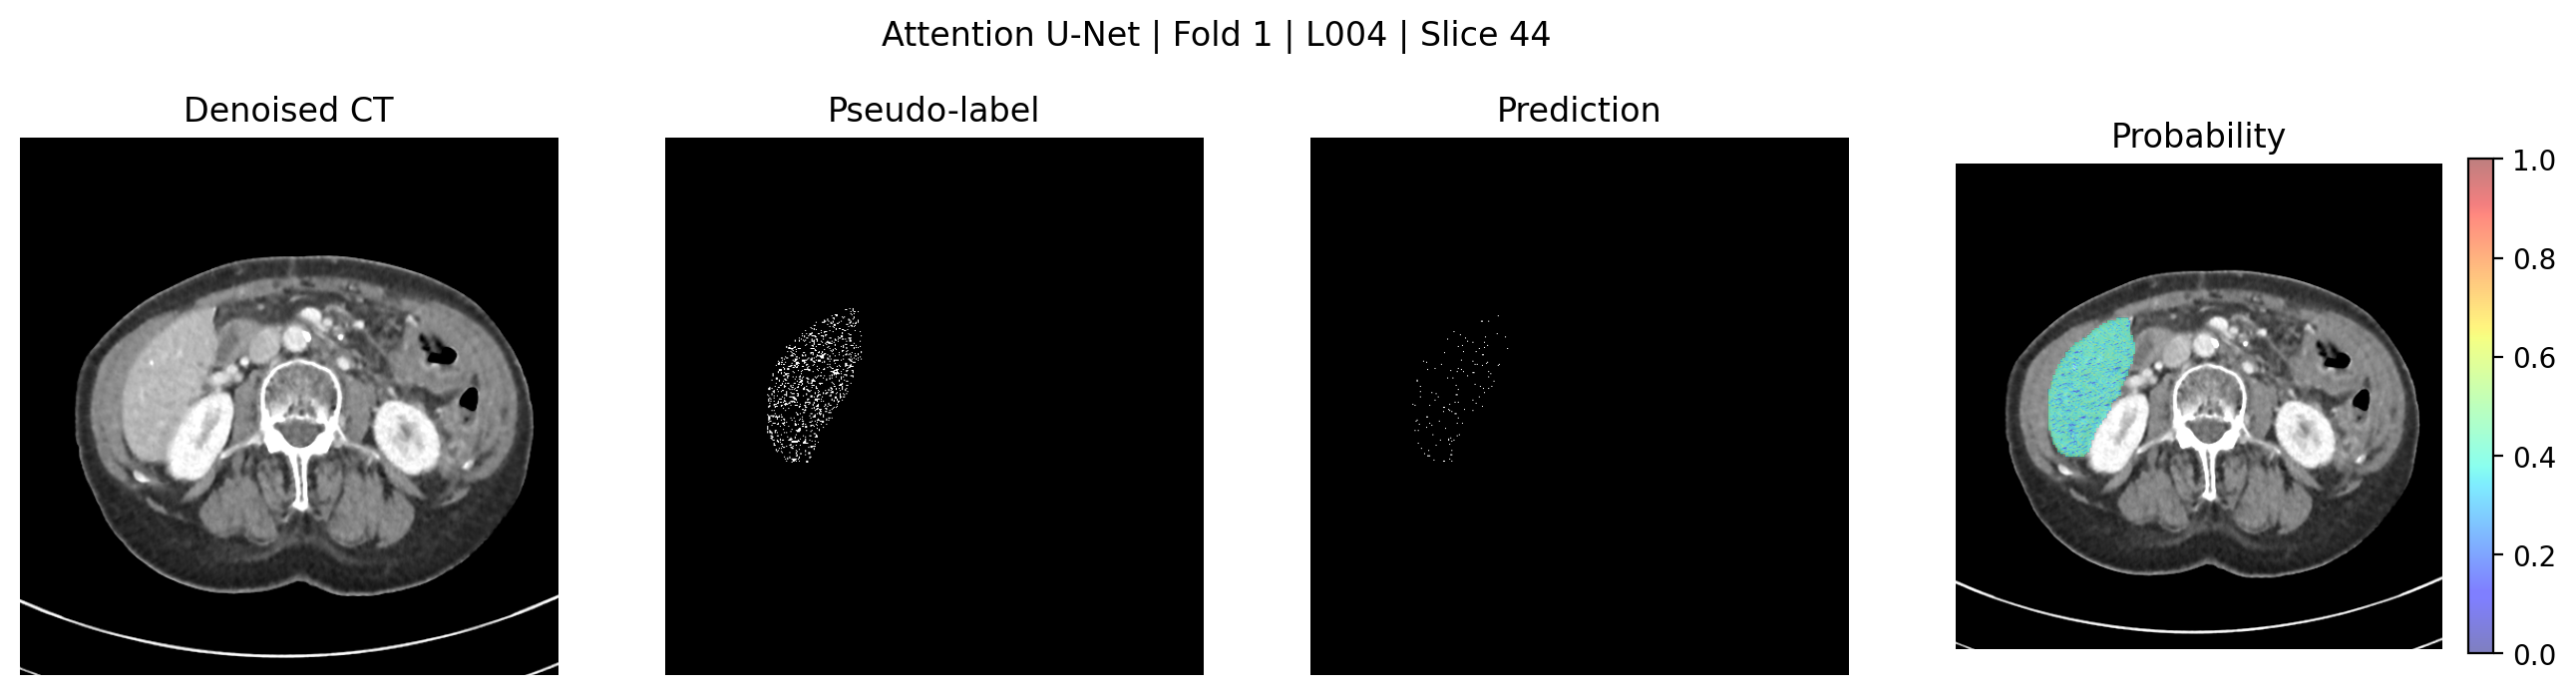

In [52]:
fold = 1
path = Path(f"/kaggle/working/CAI421_results/baseline_attention_unet/attention_unet_fold_{fold}_best.pt")
item = next(r for r in records if r["fold"] == fold and np.any(r["y"]))
model = AttentionUNet().to(DEVICE)
model.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=False)["model_state_dict"])
model.eval()
with torch.no_grad():
    x = torch.tensor(item["x"][None], dtype=torch.float32, device=DEVICE)
    prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()
den, liver = item["x"][1], item["valid"] > 0
truth = item["y"] > 0.5
pred = (prob >= 0.5) & liver
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, img, title in zip(ax, [den, truth, pred, den],
                         ["Denoised CT", "Pseudo-label", "Prediction", "Probability"]):
    a.imshow(img, cmap="gray")
    a.set_title(title)
    a.axis("off")
im = ax[3].imshow(np.ma.masked_where(~liver, prob), cmap="jet", alpha=0.5, vmin=0, vmax=1)
fig.colorbar(im, ax=ax[3], fraction=0.046)
fig.suptitle(f"Attention U-Net | Fold {fold} | {item['case_id']} | Slice {item['slice']}")
file = "/kaggle/working/attention_unet_fold1.png"
fig.savefig(file, dpi=200, bbox_inches="tight")
plt.close(fig)
display(Image(filename=file))

# Baseline 2: ResDUnet

In [57]:
BASE_ROOT = Path("/kaggle/working/CAI421_processed")
BASE_RAW = BASE_ROOT / "pairs_raw_hu"
BASE_RED = BASE_ROOT / "external_redcnn_final"
BASE_LIVER = BASE_ROOT / "totalseg_final"
BASE_LABELS = BASE_ROOT / "alteration_labels_final"
BASE_OUT = Path("/kaggle/working/CAI421_results/baseline_resdunet_inspired")
BASE_OUT.mkdir(parents=True, exist_ok=True)
SEED, CROP_SIZE, BATCH_SIZE = 42, 256, 4
EPOCHS, SAMPLES_PER_EPOCH, PATIENCE = 20, 64, 6
LEARNING_RATE, BASE_CHANNELS, THRESHOLD = 1e-4, 16, 0.50
DILATION_RATES = (16, 8, 4, 2)   
SE_REDUCTION = 8
BOTTLENECK_DROPOUT = 0.10       



In [58]:
fold_df = pd.read_csv(BASE_LABELS / "five_fold_split.csv")

assert len(fold_df) == 43 and fold_df.case_id.nunique() == 16
assert set(fold_df.fold) == set(range(1, 6))
assert fold_df.groupby("case_id").fold.nunique().eq(1).all(), "Patient leakage"
assert not fold_df.duplicated(["case_id", "slice"]).any(), "Duplicate slices"

print(f"Patients: {fold_df.case_id.nunique()} | Slices: {len(fold_df)}")

Patients: 16 | Slices: 43


In [69]:
records = []
for row in fold_df.sort_values(["case_id", "slice"]).itertuples(index=False):
    case_id, slice_id, fold = str(row.case_id), int(row.slice), int(row.fold)
    with np.load(BASE_RAW / f"{case_id}.npz") as d:
        low_hu = d["low_hu"][slice_id].astype(np.float32)
    aligned = []
    for folder, key in [(BASE_RED, "denoised_hu"),(BASE_LIVER, "mask"),(BASE_LABELS, "labels")]:
        with np.load(folder / f"{case_id}.npz") as d:
            pos = np.where(d["slices"].astype(int) == slice_id)[0]
            if len(pos) != 1:
                raise ValueError(f"{case_id}, slice {slice_id}: {key} alignment error")
            aligned.append(d[key][int(pos[0])])
    den_hu, liver, target = aligned
    den_hu = den_hu.astype(np.float32)
    liver, target = liver.astype(np.uint8), target.astype(np.uint8)
    # CHANGED: real image size instead of a hardcoded 512
    if not (low_hu.shape == den_hu.shape == liver.shape == target.shape):
        raise ValueError(f"Shape mismatch: {case_id}, slice {slice_id}")
    H, W = low_hu.shape
    if H < CROP_SIZE or W < CROP_SIZE:
        raise ValueError(f"Image {H}x{W} is smaller than the crop size {CROP_SIZE}: {case_id}")
    if not liver.any() or np.any((target > 0) & (liver == 0)):
        raise ValueError(f"Invalid mask: {case_id}, slice {slice_id}")
    low = np.clip((low_hu + 160) / 400, 0, 1)
    den = np.clip((den_hu + 160) / 400, 0, 1)
    records.append({"case_id": case_id, "slice": slice_id, "fold": fold,"x": np.stack([low, den, (den - low) * 10], axis=0).astype(np.float32),"y": target.astype(np.float32),"valid": liver.astype(np.float32)})
print(f"Loaded {len(records)} slices from {len(set(r['case_id'] for r in records))} patients.")

Loaded 43 slices from 16 patients.


In [74]:
class LiverPatchDataset(Dataset):
    def __init__(self, items, samples_per_epoch, crop, augment=True, seed=42):
        self.items = items
        self.samples_per_epoch = samples_per_epoch
        self.crop = crop
        self.augment = augment
        self.rng = np.random.default_rng(int(seed))
        self.coords = [np.argwhere(r["valid"] > 0) for r in items]
        assert all(len(c) > 0 for c in self.coords), "Empty liver mask"
    def __len__(self):
        return self.samples_per_epoch
    def __getitem__(self, index):
        i = int(self.rng.integers(len(self.items)))
        r = self.items[i]
        cy, cx = self.coords[i][self.rng.integers(len(self.coords[i]))]
        H, W = r["y"].shape
        h = self.crop // 2  # FIX: define h before using it
        y0 = int(np.clip(int(cy) - h, 0, H - self.crop))
        x0 = int(np.clip(int(cx) - h, 0, W - self.crop))
        s = (slice(y0, y0 + self.crop), slice(x0, x0 + self.crop))
        x = r["x"][:, s[0], s[1]].copy()
        y = r["y"][s].copy()
        valid = r["valid"][s].copy()
        if self.augment:
            if self.rng.random() < 0.5:
                x, y, valid = np.flip(x, -1), np.flip(y, -1), np.flip(valid, -1)
            if self.rng.random() < 0.5:
                x, y, valid = np.flip(x, -2), np.flip(y, -2), np.flip(valid, -2)
            k = int(self.rng.integers(4))
            x = np.rot90(x, k, axes=(-2, -1))
            y = np.rot90(y, k)
            valid = np.rot90(valid, k)
        return (torch.from_numpy(np.ascontiguousarray(x)).float(),torch.from_numpy(np.ascontiguousarray(y[None])).float(),torch.from_numpy(np.ascontiguousarray(valid[None])).float())

In [75]:
class SEBlock(nn.Module):
    def __init__(self, ch, reduction=8):
        super().__init__()
        hidden = max(1, ch // reduction)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(ch, hidden, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, ch, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return x * self.fc(x)
class EncoderDilatedBlock(nn.Module):
    def __init__(self, ch, dilation_rate):
        super().__init__()
        self.act = nn.ReLU(inplace=True)
        self.bn_d = nn.BatchNorm2d(ch)
        self.dilated = nn.Conv2d(ch, ch, 3, padding=dilation_rate, dilation=dilation_rate, bias=False)
        self.bn_f = nn.BatchNorm2d(2 * ch)
        self.fuse = nn.Conv2d(2 * ch, ch, 1, bias=False)
    def forward(self, x):
        d = self.dilated(self.act(self.bn_d(x)))
        return self.fuse(self.act(self.bn_f(torch.cat([x, d], dim=1))))
class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, dropout=0.0, se_reduction=8, first=False):
        super().__init__()
        self.first = first  # kept as a flag for documenting the input-stage CT adaptation
        self.bn1 = nn.BatchNorm2d(in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.activation = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()
        self.se = SEBlock(out_ch, se_reduction)
        self.shortcut = (
            nn.Identity() if (in_ch == out_ch and stride == 1)
            else nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False)
        )
    def forward(self, x):
        # Pre-activation (BN -> ReLU -> Conv) in every residual block.
        # The signed difference channel is retained in the input tensor; as in the
        # original pre-activation design, the residual branch receives BN + ReLU.
        h = self.activation(self.bn1(x))
        h = self.dropout(self.conv1(h))
        h = self.conv2(self.activation(self.bn2(h)))
        return self.se(h) + self.shortcut(x)
class ResDUNetInspired(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, base=16,
                 dilation_rates=(16, 8, 4, 2), se_reduction=8, bottleneck_dropout=0.10):
        super().__init__()
        b = base
        r1, r2, r3, r4 = dilation_rates

        self.enc1 = nn.Sequential(
            ResidualBlock(in_channels, b, se_reduction=se_reduction, first=True),
            EncoderDilatedBlock(b, r1))
        self.enc2 = nn.Sequential(
            ResidualBlock(b, 2 * b, stride=2, se_reduction=se_reduction),
            EncoderDilatedBlock(2 * b, r2))
        self.enc3 = nn.Sequential(
            ResidualBlock(2 * b, 4 * b, stride=2, se_reduction=se_reduction),
            EncoderDilatedBlock(4 * b, r3))
        self.enc4 = nn.Sequential(
            ResidualBlock(4 * b, 8 * b, stride=2, se_reduction=se_reduction),
            EncoderDilatedBlock(8 * b, r4))
        self.bottleneck = ResidualBlock(
            8 * b, 16 * b, stride=2, dropout=bottleneck_dropout, se_reduction=se_reduction)
        self.up4 = nn.ConvTranspose2d(16 * b, 8 * b, 2, stride=2)
        self.dec4 = ResidualBlock(16 * b, 8 * b, se_reduction=se_reduction)
        self.up3 = nn.ConvTranspose2d(8 * b, 4 * b, 2, stride=2)
        self.dec3 = ResidualBlock(8 * b, 4 * b, se_reduction=se_reduction)
        self.up2 = nn.ConvTranspose2d(4 * b, 2 * b, 2, stride=2)
        self.dec2 = ResidualBlock(4 * b, 2 * b, se_reduction=se_reduction)
        self.up1 = nn.ConvTranspose2d(2 * b, b, 2, stride=2)
        self.dec1 = ResidualBlock(2 * b, b, se_reduction=se_reduction)
        # pre-activation networks end with BN-ReLU before the output layer
        self.head = nn.Sequential(
            nn.BatchNorm2d(b), nn.ReLU(inplace=True), nn.Conv2d(b, out_channels, 1))
    def forward(self, x):
        h, w = x.shape[-2:]
        ph, pw = (-h) % 16, (-w) % 16            # four stride-2 stages
        if ph or pw:
            x = F.pad(x, (0, pw, 0, ph), mode="replicate")
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        z = self.bottleneck(e4)
        d4 = self.dec4(torch.cat([self.up4(z), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)[..., :h, :w]        # logits
def build_model():
    return ResDUNetInspired(in_channels=3, out_channels=1, base=BASE_CHANNELS,
                            dilation_rates=DILATION_RATES, se_reduction=SE_REDUCTION,
                            bottleneck_dropout=BOTTLENECK_DROPOUT)
_m = build_model().to(DEVICE).eval()
with torch.no_grad():
    for _s in (CROP_SIZE, 250):
        _o = _m(torch.randn(2, 3, _s, _s, device=DEVICE))
        assert _o.shape == (2, 1, _s, _s), _o.shape
print("Output shapes OK | parameters:", sum(p.numel() for p in _m.parameters()))
del _m



Output shapes OK | parameters: 2298563


In [76]:
class MaskedBCEDiceLoss(nn.Module):
    def __init__(self, pos_weight=3.0, dice_weight=1.0):
        super().__init__()
        self.register_buffer("pos_weight", torch.tensor(float(pos_weight)))
        self.dice_weight = dice_weight
    def forward(self, logits, target, valid):
        bce = F.binary_cross_entropy_with_logits(logits, target, pos_weight=self.pos_weight, reduction="none")
        bce = (bce * valid).sum() / valid.sum().clamp_min(1.0)
        prob, target = torch.sigmoid(logits) * valid, target * valid
        dims = (1, 2, 3)
        intersection = (prob * target).sum(dims)
        denom = prob.sum(dims) + target.sum(dims)
        dice = (2 * intersection + 1e-6) / (denom + 1e-6)
        return bce + self.dice_weight * (1 - dice.mean())
@torch.no_grad()
def evaluate_resdunet_model(model, items):
    model.eval()
    tp = fp = fn = 0
    losses = []
    criterion = MaskedBCEDiceLoss().to(DEVICE)
    for item in items:
        x = torch.from_numpy(item["x"][None]).float().to(DEVICE)
        y = torch.from_numpy(item["y"][None, None]).float().to(DEVICE)
        valid = torch.from_numpy(item["valid"][None, None]).float().to(DEVICE)
        logits = model(x)
        losses.append(criterion(logits, y, valid).item())
        pred = (torch.sigmoid(logits) >= THRESHOLD) & (valid > 0)
        truth = (y > 0.5) & (valid > 0)
        tp += int((pred & truth).sum().item())
        fp += int((pred & ~truth & (valid > 0)).sum().item())
        fn += int((~pred & truth).sum().item())
        del x, y, valid, logits
    eps = 1e-8
    return {
        "loss": float(np.mean(losses)),
        "dice": 2 * tp / (2 * tp + fp + fn + eps),
        "iou": tp / (tp + fp + fn + eps),
        "precision": tp / (tp + fp + eps),
        "recall": tp / (tp + fn + eps),
        "tp": tp, "fp": fp, "fn": fn
    }

In [77]:
def set_seed(seed):
    seed = int(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
FOLDS = sorted(map(int, fold_df["fold"].unique()))
def nested_split(test_fold):
    val_fold = FOLDS[(FOLDS.index(test_fold) + 1) % len(FOLDS)]
    train_folds = [f for f in FOLDS if f not in (test_fold, val_fold)]
    return train_folds, val_fold, test_fold
fold_results, history_rows, split_info = [], [], {}
for fold in FOLDS:
    train_folds, val_fold, _ = nested_split(fold)
    train_items = [r for r in records if r["fold"] in train_folds]
    val_items = [r for r in records if r["fold"] == val_fold]
    test_items = [r for r in records if r["fold"] == fold]
    train_ids = {r["case_id"] for r in train_items}
    val_ids = {r["case_id"] for r in val_items}
    test_ids = {r["case_id"] for r in test_items}
    assert train_ids.isdisjoint(val_ids)
    assert train_ids.isdisjoint(test_ids)
    assert val_ids.isdisjoint(test_ids)
    split_info[fold] = {
        "train_folds": train_folds,
        "val_fold": val_fold,
        "train_patients": sorted(train_ids),
        "val_patients": sorted(val_ids),
        "test_patients": sorted(test_ids)
    }
    print(f"\n{'='*12} Test {fold} | Val {val_fold} | Train {train_folds} {'='*12}")
    set_seed(SEED + fold)
    train_ds = LiverPatchDataset(train_items, SAMPLES_PER_EPOCH, CROP_SIZE, True, SEED + fold)
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=False,num_workers=0, pin_memory=DEVICE.type == "cuda")
    model = build_model().to(DEVICE)
    criterion = MaskedBCEDiceLoss(3.0, 1.0).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
    best_dice, best_epoch, bad_epochs = -1.0, 0, 0
    best_path = BASE_OUT / f"resdunet_inspired_fold_{fold}_best.pt"
    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for x, y, valid in loader:
            x, y, valid = (t.to(DEVICE, non_blocking=True) for t in (x, y, valid))
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y, valid)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            losses.append(loss.item())
        metrics = evaluate_resdunet_model(model, val_items)
        scheduler.step(metrics["dice"])
        history_rows.append({
            "test_fold": fold,
            "val_fold": val_fold,
            "epoch": epoch,
            "train_loss": float(np.mean(losses)),
            "val_loss": metrics["loss"],
            "val_dice": metrics["dice"],
            "val_iou": metrics["iou"]})
        print(
            f"Test {fold} | Epoch {epoch:02d}/{EPOCHS} | "
            f"Train {np.mean(losses):.4f} | "
            f"Val Dice {metrics['dice']:.4f} | "
            f"Val IoU {metrics['iou']:.4f}"
        )
        if metrics["dice"] > best_dice:
            best_dice, best_epoch, bad_epochs = metrics["dice"], epoch, 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "test_fold": fold,
                "val_fold": val_fold,
                "epoch": epoch,
                "validation_metrics": metrics,
                "threshold": THRESHOLD,
                "dilation_rates": list(DILATION_RATES),
                "input_channels": ["low_dose", "external_redcnn", "difference_x10"]}, best_path)
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print("Early stopping.")
                break
    checkpoint = torch.load(best_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    result = evaluate_resdunet_model(model, val_items)
    result = {f"val_{k}": v for k, v in result.items()}
    result.update({
        "fold": fold,
        "val_fold": val_fold,
        "best_epoch": best_epoch,
        "train_patients": len(train_ids),
        "val_patients": len(val_ids),
        "test_patients": len(test_ids),
        "train_slices": len(train_items),
        "val_slices": len(val_items),
        "test_slices": len(test_items),
        "checkpoint": str(best_path)})
    fold_results.append(result)
    print(
        f"Best epoch {best_epoch} | "
        f"Val Dice {result['val_dice']:.4f} | "
        f"Val IoU {result['val_iou']:.4f}"
    )
    del model, optimizer, criterion, loader, train_ds
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


============ Test 1 | Val 2 | Train [3, 4, 5] ============
Test 1 | Epoch 01/20 | Train 1.6821 | Val Dice 0.1226 | Val IoU 0.0653
Test 1 | Epoch 02/20 | Train 1.6653 | Val Dice 0.1329 | Val IoU 0.0712
Test 1 | Epoch 03/20 | Train 1.6529 | Val Dice 0.1124 | Val IoU 0.0595
Test 1 | Epoch 04/20 | Train 1.6479 | Val Dice 0.1137 | Val IoU 0.0603
Test 1 | Epoch 05/20 | Train 1.6461 | Val Dice 0.1259 | Val IoU 0.0672
Test 1 | Epoch 06/20 | Train 1.6427 | Val Dice 0.1266 | Val IoU 0.0676
Test 1 | Epoch 07/20 | Train 1.6348 | Val Dice 0.1234 | Val IoU 0.0658
Test 1 | Epoch 08/20 | Train 1.6343 | Val Dice 0.1204 | Val IoU 0.0641
Early stopping.
Best epoch 2 | Val Dice 0.1329 | Val IoU 0.0712

============ Test 2 | Val 3 | Train [1, 4, 5] ============
Test 2 | Epoch 01/20 | Train 1.6837 | Val Dice 0.2588 | Val IoU 0.1487
Test 2 | Epoch 02/20 | Train 1.6643 | Val Dice 0.1007 | Val IoU 0.0530
Test 2 | Epoch 03/20 | Train 1.6546 | Val Dice 0.0669 | Val IoU 0.0346
Test 2 | Epoch 04/20 | Train 1.6474

In [79]:
test_predictions = []

for fold in FOLDS:
    path = BASE_OUT / f"resdunet_inspired_fold_{fold}_best.pt"
    ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
    assert ckpt["test_fold"] == fold

    model = build_model().to(DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()

    test_items = [r for r in records if r["fold"] == fold]

    with torch.no_grad():
        for item in test_items:
            x = torch.as_tensor(item["x"][None], dtype=torch.float32, device=DEVICE)
            prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()

            test_predictions.append({
                "fold": fold,
                "case_id": item["case_id"],
                "slice": item["slice"],
                "prob": prob,
                "truth": item["y"],
                "valid": item["valid"]
            })

    print(f"Fold {fold}: {len(test_items)} test slices")
    del model

print("Total predictions:", len(test_predictions))


Fold 1: 14 test slices
Fold 2: 10 test slices
Fold 3: 7 test slices
Fold 4: 4 test slices
Fold 5: 8 test slices
Total predictions: 43


In [80]:
results = []
for fold in FOLDS:
    items = [r for r in test_predictions if r["fold"] == fold]
    tp = fp = fn = 0
    probs, labels = [], []
    for item in items:
        valid = item["valid"] > 0
        truth = (item["truth"] > 0.5) & valid
        pred = (item["prob"] >= THRESHOLD) & valid
        tp += np.sum(pred & truth)
        fp += np.sum(pred & ~truth & valid)
        fn += np.sum(~pred & truth)
        probs.append(item["prob"][valid])
        labels.append(truth[valid])
    probs = np.concatenate(probs)
    labels = np.concatenate(labels)
    eps = 1e-8
    results.append({
        "fold": fold,
        "dice": 2 * tp / (2 * tp + fp + fn + eps),
        "iou": tp / (tp + fp + fn + eps),
        "precision": tp / (tp + fp + eps),
        "recall": tp / (tp + fn + eps),
        "auprc": average_precision_score(labels, probs) if labels.any() else np.nan,
        "test_positive_pixels": int(labels.sum()),
        "test_valid_pixels": int(labels.size)})
test_df = pd.DataFrame(results)
test_df = test_df.merge(pd.DataFrame(fold_results), on="fold")     # adds validation info per fold
metrics = ["dice", "iou", "precision", "recall", "auprc"]
summary = test_df[metrics].agg(["mean", "std"]).round(4)
test_df.to_csv(BASE_OUT / "resdunet_5fold_test_metrics.csv", index=False)
summary.to_csv(BASE_OUT / "resdunet_5fold_test_summary.csv")
print("RESDUNET-INSPIRED: HELD-OUT TEST FOLDS (nested 5-fold)")
display(test_df[["fold", "val_fold", "best_epoch"] + metrics + ["val_dice"]].round(4))
display(summary)

RESDUNET-INSPIRED: HELD-OUT TEST FOLDS (nested 5-fold)


,fold,val_fold,best_epoch,dice,iou,precision,recall,auprc,val_dice
0,1,2,2,0.1055,0.0557,0.1792,0.0747,0.1815,0.1329
1,2,3,1,0.2626,0.1511,0.1944,0.4046,0.1914,0.2588
2,3,4,1,0.2939,0.1722,0.1723,0.9993,0.1842,0.3250
3,4,5,1,0.3121,0.1849,0.1931,0.8133,0.1917,0.2838
4,5,1,1,0.2869,0.1674,0.1674,1.0000,0.1499,0.3020


,dice,iou,precision,recall,auprc
mean,0.2522,0.1463,0.1813,0.6584,0.1797
std,0.0839,0.0521,0.0121,0.4068,0.0173


## Overall results — (validation and test)


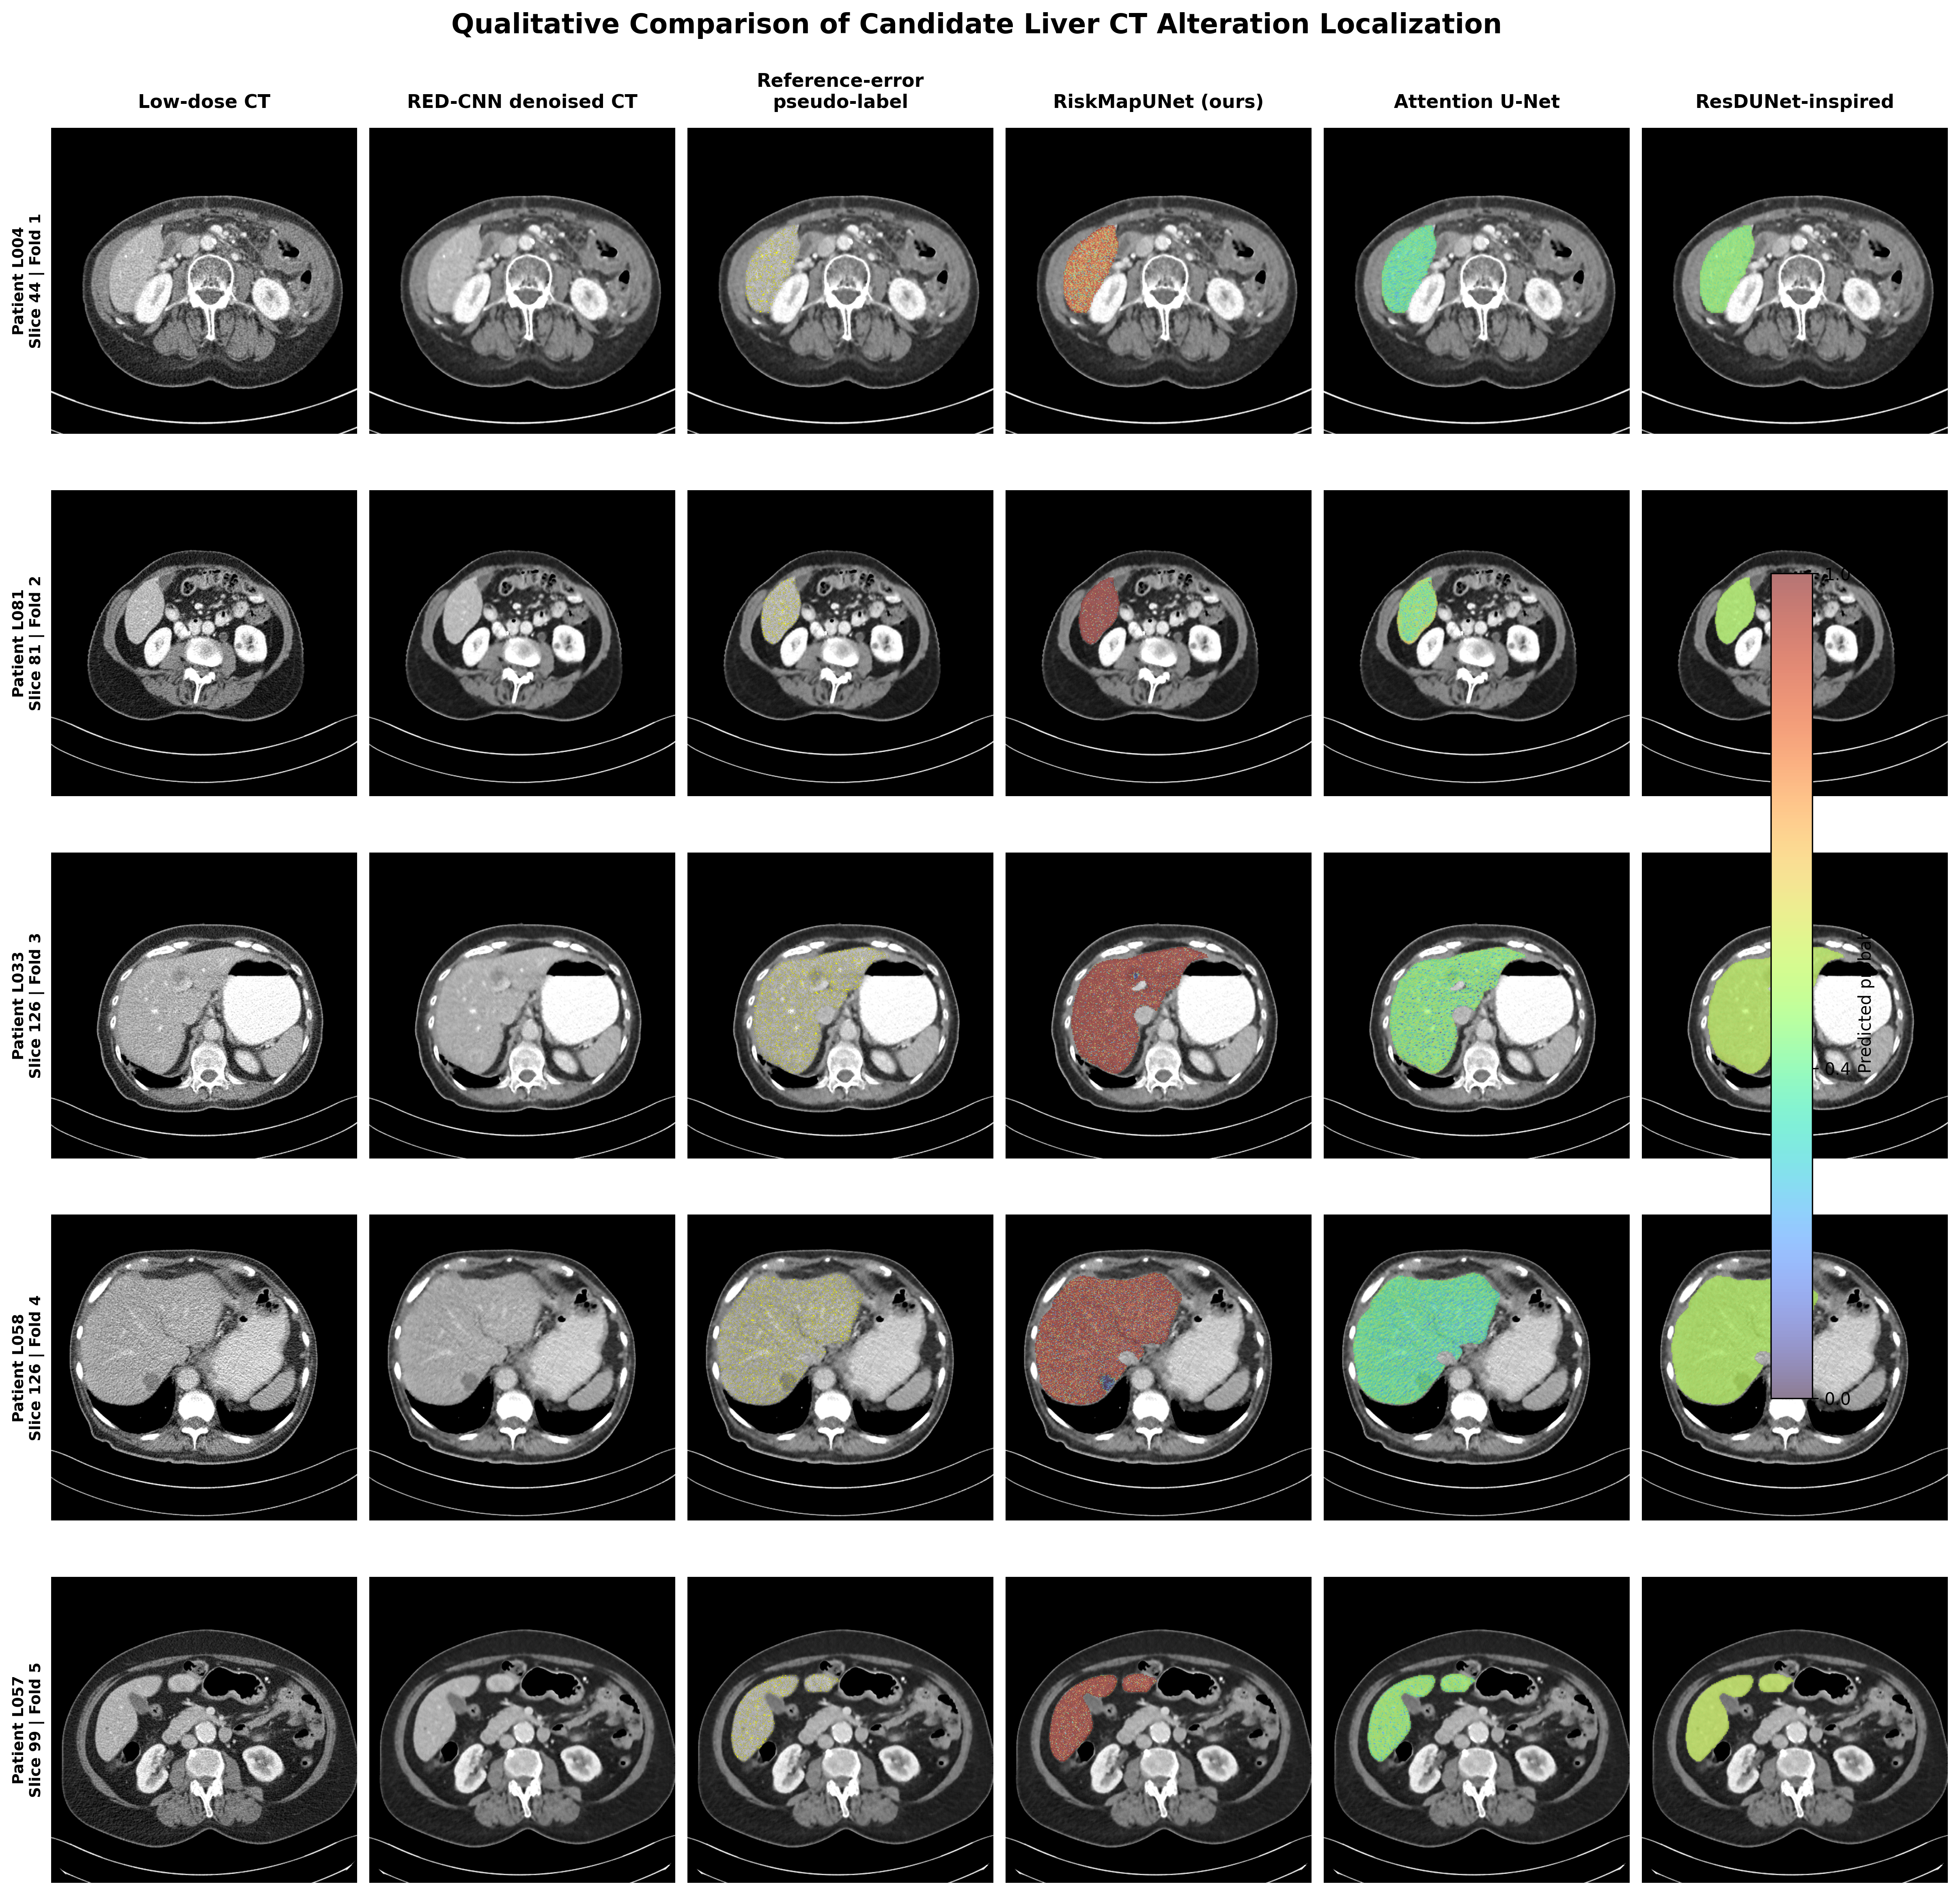

In [83]:
OUT = Path("/kaggle/working/CAI421_results/publication_figures")
OUT.mkdir(parents=True, exist_ok=True)
models = {
    "RiskMapUNet": {
        "class": lambda: RiskMapUNet(),
        "path": lambda f: Path(f"/kaggle/working/RiskMapUNet_v2_final/fold_{f}.pt")},
    "Attention U-Net": {
        "class": lambda: AttentionUNet(),
        "path": lambda f: Path(
            f"/kaggle/working/CAI421_results/baseline_attention_unet/"
            f"attention_unet_fold_{f}_best.pt")},
    "ResDUNet": {
        "class": lambda: ResDUNetInspired(base=BASE_CHANNELS),
        "path": lambda f: Path(
            f"/kaggle/working/CAI421_results/baseline_resdunet_inspired/"
            f"resdunet_inspired_fold_{f}_best.pt")}}
samples = []
for fold in range(1, 6):
    candidates = [
        r for r in records
        if r["fold"] == fold
        and np.any((r["y"] > 0.5) & (r["valid"] > 0))]
    if not candidates:
        raise ValueError(f"No positive liver slice in fold {fold}")
    samples.append(candidates[0])
def load_model(name, fold):
    spec = models[name]
    path = spec["path"](fold)
    if not path.exists():
        raise FileNotFoundError(path)
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    model = spec["class"]().to(DEVICE)
    state = checkpoint.get("model_state_dict", checkpoint) \
        if isinstance(checkpoint, dict) else checkpoint
    model.load_state_dict(state)
    model.eval()
    return model
def predict_sample(name, model, item):
    if name == "RiskMapUNet":
        # Use exactly the input construction from RiskMapUNet training.
        low = torch.as_tensor(item["x"][0][None], dtype=torch.float32, device=DEVICE)
        den = torch.as_tensor(item["x"][1][None], dtype=torch.float32, device=DEVICE)
        x = make_input(low, den)
    else:
        x = torch.as_tensor(item["x"][None], dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        prob = torch.sigmoid(model(x))[0, 0].cpu().numpy()
    return np.where(item["valid"] > 0, prob, np.nan)
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"})
fig, axes = plt.subplots(5, 6, figsize=(19, 16), dpi=150)
titles = [
    "Low-dose CT",
    "RED-CNN denoised CT",
    "Reference-error\npseudo-label",
    "RiskMapUNet (ours)",
    "Attention U-Net",
    "ResDUNet-inspired"]
for j, title in enumerate(titles):
    axes[0, j].set_title(title, fontweight="bold", pad=12)
for i, item in enumerate(samples):
    fold = item["fold"]
    low = item["x"][0]
    den = item["x"][1]
    truth = (item["y"] > 0.5) & (item["valid"] > 0)
    axes[i, 0].imshow(low, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].imshow(den, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].imshow(den, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].imshow(np.ma.masked_where(~truth, truth),cmap="autumn", alpha=0.8, vmin=0, vmax=1)
    for j, name in enumerate(models, start=3):
        model = load_model(name, fold)
        prob = predict_sample(name, model, item)
        axes[i, j].imshow(den, cmap="gray", vmin=0, vmax=1)
        im = axes[i, j].imshow(np.ma.masked_invalid(prob),cmap="turbo", alpha=0.55, vmin=0, vmax=1)
        del model
    axes[i, 0].set_ylabel(
        f"Patient {item['case_id']}\n"
        f"Slice {item['slice']} | Fold {fold}",fontsize=9, fontweight="bold")
    for ax in axes[i]:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
fig.colorbar(im, ax=axes[:, 3:].ravel().tolist(),shrink=0.55, pad=0.015, label="Predicted probability")
fig.suptitle("Qualitative Comparison of Candidate Liver CT Alteration Localization",fontsize=16, fontweight="bold", y=0.995)
fig.subplots_adjust(left=0.10, right=0.92, top=0.94,bottom=0.03, wspace=0.04, hspace=0.12)
fig.savefig(OUT / "figure1_matched_heatmaps.png",dpi=300, bbox_inches="tight")
fig.savefig(OUT / "figure1_matched_heatmaps.pdf",bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(OUT / "figure1_matched_heatmaps.png")))

Grouped bar chart of Dice, IoU and AUC-PR for the three models.

- **Precision:** out of all the pixels the model predicted as altered, how many match the pseudo-label
- **Recall:** out of all the pseudo-label pixels, how many the model found
- **AUC-PR:** area under the precision-recall curve, useful here because the positive pixels are the minority

In [86]:
from pathlib import Path
from IPython.display import display, Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUT = Path("/kaggle/working/CAI421_results/publication_figures")
OUT.mkdir(parents=True, exist_ok=True)

models = ["Attention U-Net", "ResDUNet-inspired", "RiskMapUNet"]
keywords = {
    "Attention U-Net": ["attention"],
    "ResDUNet-inspired": ["resdunet", "resd"],
    "RiskMapUNet": ["riskmap"]
}

rows = []
found = {}

for name in models:
    candidates = [
        p for p in Path("/kaggle/working").rglob("*.csv")
        if any(k in str(p).lower() for k in keywords[name])
        and any(k in p.name.lower() for k in ("metric", "result", "summary"))
    ]

    valid_files = []

    for path in candidates:
        try:
            df = pd.read_csv(path)
            cols = {c.lower(): c for c in df.columns}

            if "dice" not in cols or "iou" not in cols:
                continue

            auc_col = next(
                (cols[k] for k in ("auprc", "auc_pr", "pr_auc", "ap")
                 if k in cols), None
            )

            if auc_col is None:
                continue

            # Prefer explicitly saved TEST metrics.
            if "test" not in path.name.lower():
                continue

            valid_files.append((path, df, cols, auc_col))

        except (OSError, ValueError, pd.errors.ParserError):
            continue

    if not valid_files:
        print(f"No suitable test-metrics CSV found for {name}")
        print("Possible files:", [str(p) for p in candidates])
        continue

    if len(valid_files) > 1:
        print(f"Multiple matching files for {name}:")
        for p, _, _, _ in valid_files:
            print(" ", p)
        continue

    path, df, cols, auc_col = valid_files[0]
    found[name] = str(path)
    print(f"{name}: {path}")

    for label, column in [
        ("DICE", cols["dice"]),
        ("IOU", cols["iou"]),
        ("AUC-PR", auc_col)
    ]:
        values = pd.to_numeric(df[column], errors="coerce").dropna()

        rows.append({
            "Model": name,
            "Metric": label,
            "Mean": values.mean(),
            "SD": values.std(),
            "N": len(values)
        })

plot_df = pd.DataFrame(rows)

if set(found) != set(models):
    print("\nCannot produce a complete comparison yet.")
    print("Available metric files:")
    display(plot_df)
else:
    # Require five test-fold results per model.
    assert (plot_df["N"] == 5).all(), (
        "Expected exactly five test-fold metric values per model."
    )

    plot_df.to_csv(OUT / "figure2_metrics.csv", index=False)

    metric_order = ["DICE", "IOU", "AUC-PR"]
    colors = {
        "DICE": "#2B6CB0",
        "IOU": "#38A169",
        "AUC-PR": "#D69E2E"
    }

    fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)
    x = np.arange(len(models))
    width = 0.24

    for i, metric in enumerate(metric_order):
        subset = plot_df[plot_df["Metric"] == metric].set_index("Model")
        values = subset.loc[models, "Mean"].to_numpy()
        errors = subset.loc[models, "SD"].to_numpy()

        bars = ax.bar(
            x + (i - 1) * width,
            values,
            width,
            yerr=errors,
            capsize=4,
            label=metric,
            color=colors[metric],
            edgecolor="white"
        )

        for bar, value in zip(bars, values):
            ax.annotate(
                f"{value:.3f}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                fontsize=9
            )

    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.set_title("Segmentation and Detection Performance Comparison")
    ax.legend(frameon=False, ncol=3)
    ax.grid(axis="y", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.tight_layout()

    png = OUT / "figure2_metric_comparison.png"
    fig.savefig(png, dpi=300, bbox_inches="tight")
    fig.savefig(OUT / "figure2_metric_comparison.pdf", bbox_inches="tight")

    plt.close(fig)
    display(Image(filename=str(png)))
    display(plot_df.round(4))

No suitable test-metrics CSV found for Attention U-Net
Possible files: ['/kaggle/working/CAI421_results/baseline_attention_unet/attention_unet_5fold_summary.csv', '/kaggle/working/CAI421_results/baseline_attention_unet/attention_unet_5fold_metrics.csv']
Multiple matching files for ResDUNet-inspired:
  /kaggle/working/CAI421_results/baseline_resdunet_inspired/resdunet_5fold_test_metrics.csv
  /kaggle/working/CAI421_results/baseline_resdunet_inspired/resdunet_5fold_test_summary.csv
No suitable test-metrics CSV found for RiskMapUNet
Possible files: ['/kaggle/working/RiskMapUNet_v2_final/five_fold_results.csv']

Cannot produce a complete comparison yet.
Available metric files:


""


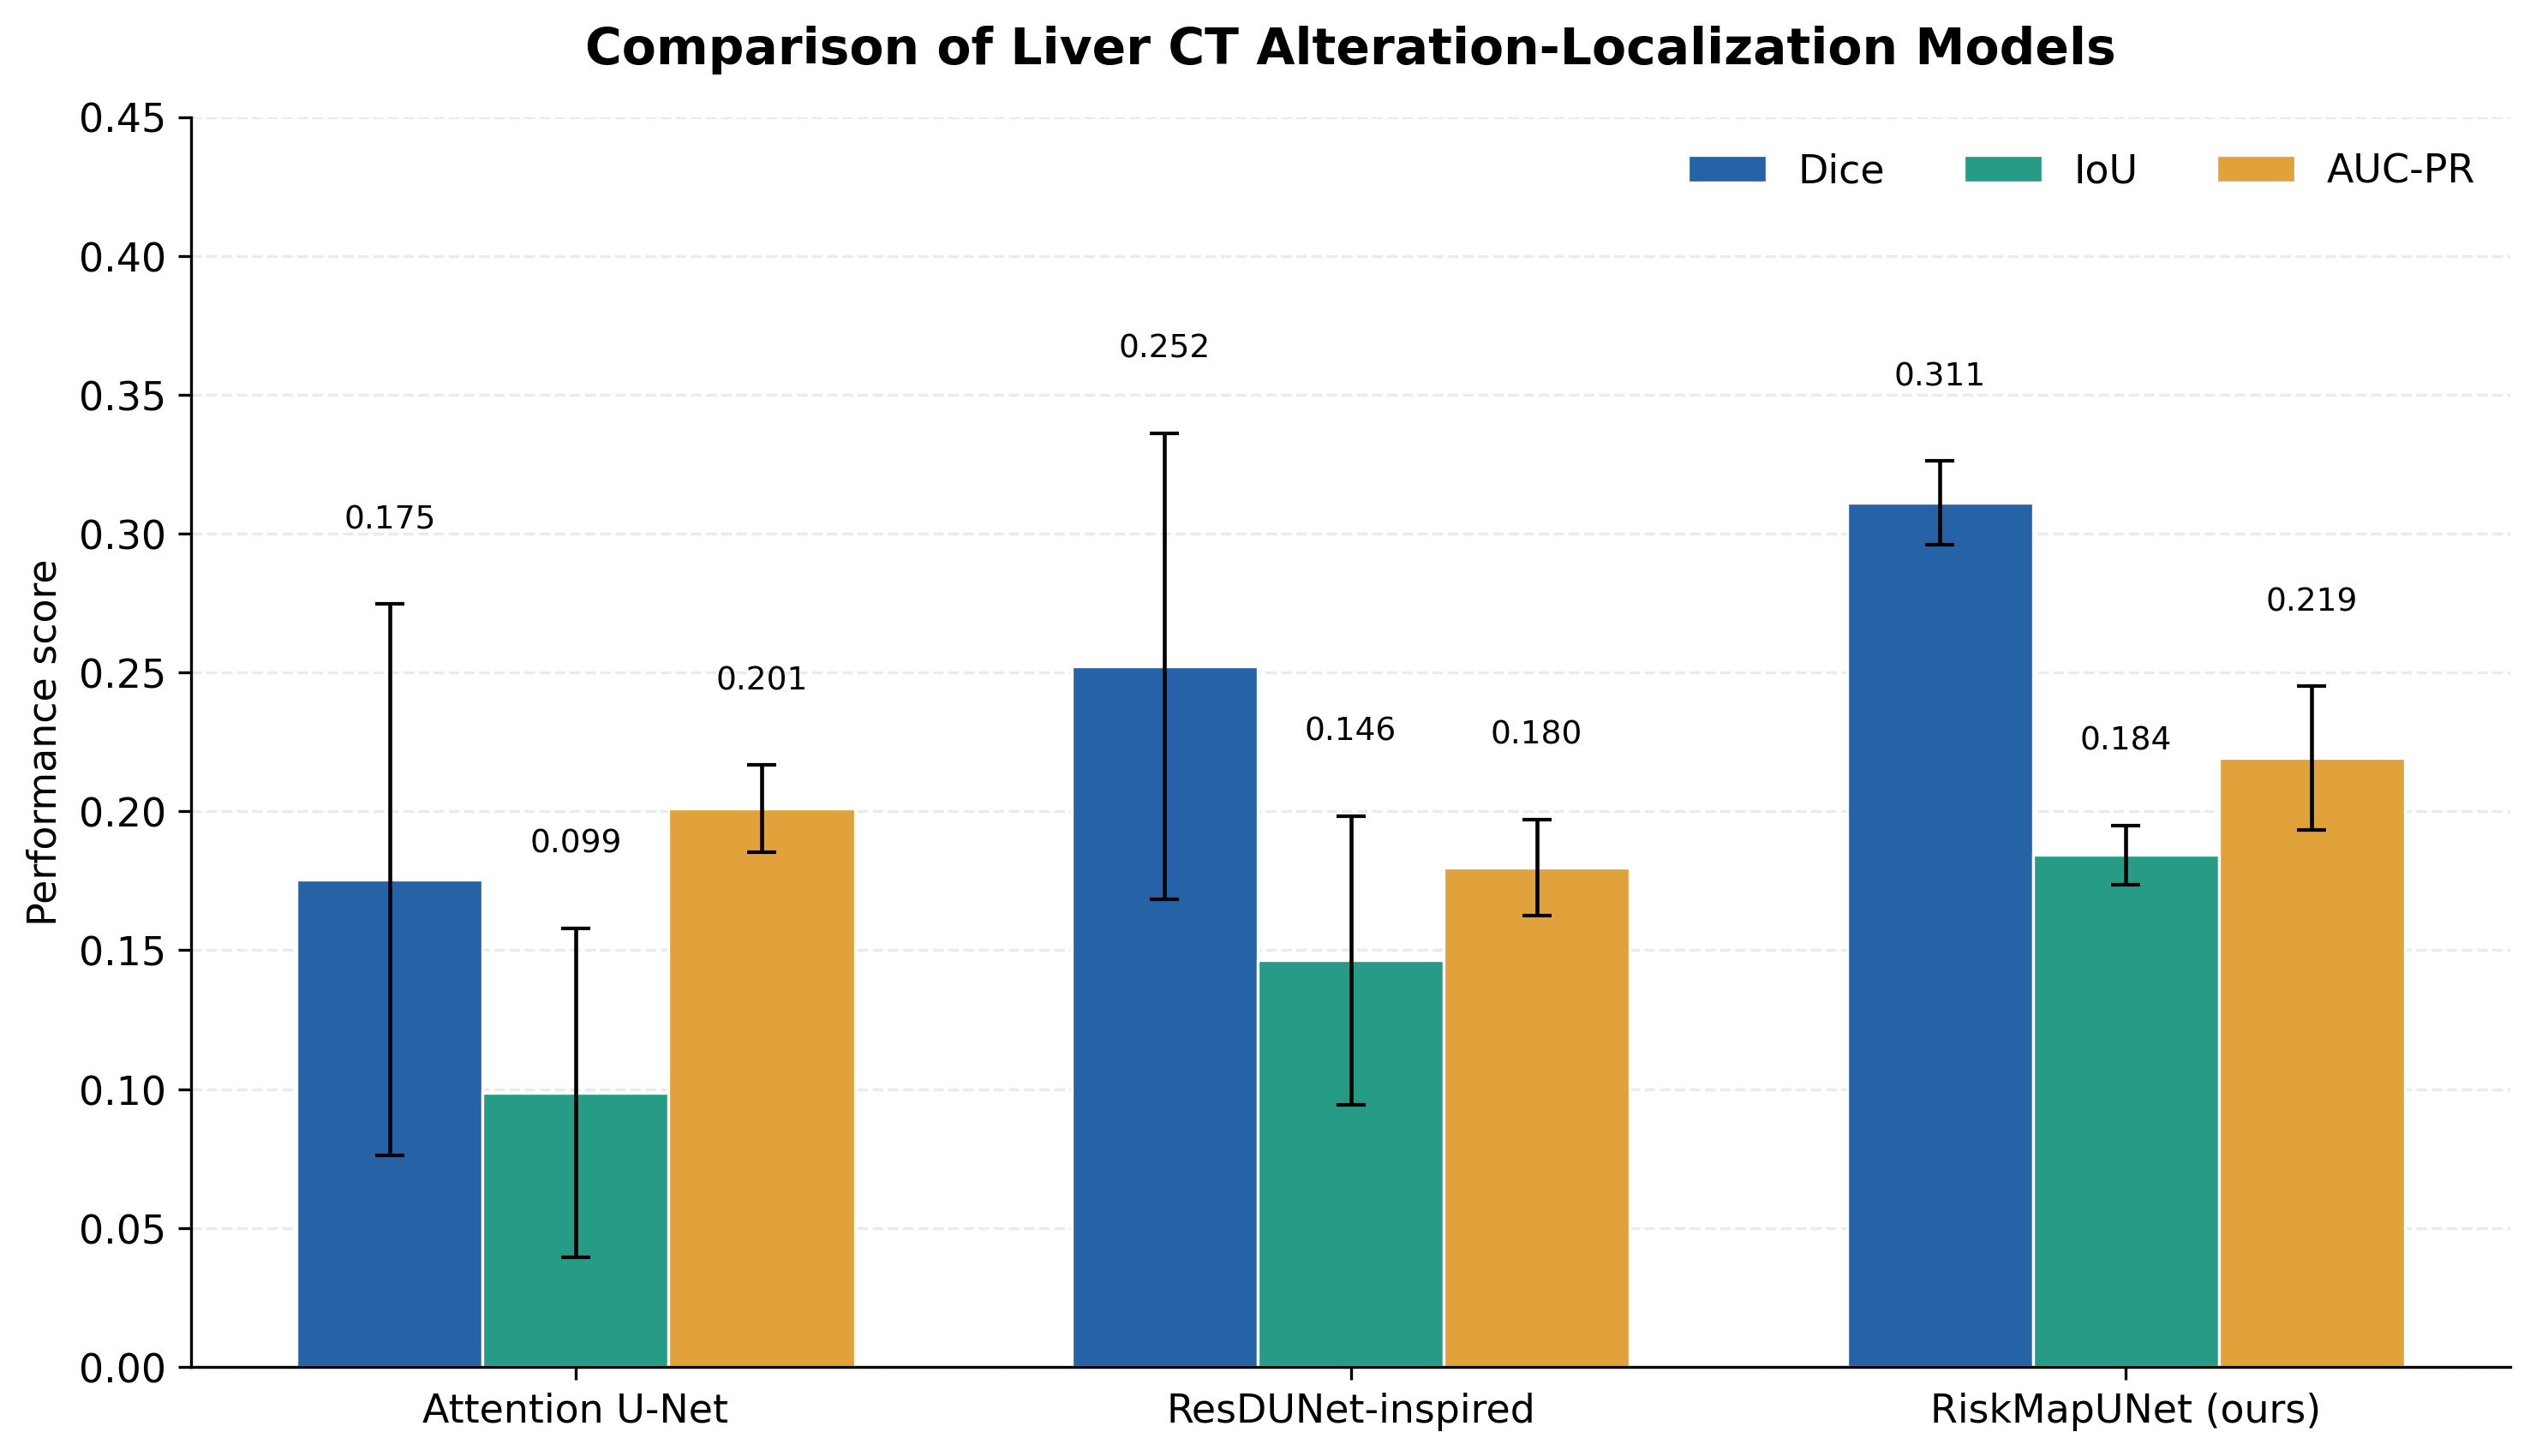

Metric,auprc,dice,iou
Model,,,
Attention U-Net,0.2010,0.1754,0.0987
ResDUNet-inspired,0.1797,0.2522,0.1463
RiskMapUNet (ours),0.2191,0.3110,0.1842


Saved to: /kaggle/working/CAI421_results/publication_figures


In [88]:
OUT = Path("/kaggle/working/CAI421_results/publication_figures")
OUT.mkdir(parents=True, exist_ok=True)
metric_files = {
    "Attention U-Net": Path(
        "/kaggle/working/CAI421_results/baseline_attention_unet/"
        "attention_unet_5fold_metrics.csv"
    ),
    "ResDUNet-inspired": Path(
        "/kaggle/working/CAI421_results/baseline_resdunet_inspired/"
        "resdunet_5fold_test_metrics.csv"
    ),
    "RiskMapUNet (ours)": Path(
        "/kaggle/working/RiskMapUNet_v2_final/"
        "five_fold_results.csv")}
metrics = ["dice", "iou", "auprc"]
rows = []
for model, path in metric_files.items():
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip().str.lower()
    if "auprc" not in df.columns and "auc_pr" in df.columns:
        df = df.rename(columns={"auc_pr": "auprc"})
    for metric in metrics:
        if metric not in df.columns:
            raise ValueError(f"{model}: missing {metric}")
        values = pd.to_numeric(df[metric], errors="coerce").dropna()
        if len(values) != 5:
            raise ValueError(f"{model}: expected 5 folds, found {len(values)}")
        rows.append({
            "Model": model,
            "Metric": metric,
            "Mean": values.mean(),
            "SD": values.std(ddof=1)})
plot_df = pd.DataFrame(rows)
plot_df.to_csv(OUT / "figure2_metrics.csv", index=False)
models = list(metric_files)
labels = {"dice": "Dice", "iou": "IoU", "auprc": "AUC-PR"}
colors = {
    "dice": "#2563A6",
    "iou": "#269C87",
    "auprc": "#E2A23B"}
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"})
fig, ax = plt.subplots(figsize=(10, 5.8), dpi=150)
x = np.arange(len(models))
width = 0.24
for i, metric in enumerate(metrics):
    subset = plot_df[plot_df["Metric"] == metric].set_index("Model").loc[models]
    means = subset["Mean"].to_numpy()
    stds = subset["SD"].to_numpy()
    bars = ax.bar(x + (i - 1) * width,means,width,yerr=stds,capsize=4,color=colors[metric],label=labels[metric],edgecolor="white",linewidth=0.8,error_kw={"elinewidth": 1.1})
    for bar, value, sd in zip(bars, means, stds):
        ax.text(bar.get_x() + bar.get_width() / 2,value + sd + 0.025,f"{value:.3f}",ha="center",va="bottom",fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel("Performance score")
ax.set_ylim(0, 0.45)
ax.set_title("Comparison of Liver CT Alteration-Localization Models",fontsize=14,fontweight="bold",pad=15)
ax.legend(frameon=False, ncol=3, loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
png = OUT / "figure2_dice_iou_auprc.png"
pdf = OUT / "figure2_dice_iou_auprc.pdf"
fig.savefig(png, dpi=300, bbox_inches="tight")
fig.savefig(pdf, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(png)))
display(plot_df.pivot(index="Model",columns="Metric",values="Mean").round(4))
print("Saved to:", OUT)

**Observations**
1. RiskMapUNet achieves the highest Dice and IoU meaning it has better masking overlap
2. RiskMapUNet's AUC-PR is only 0.2175-0.2140= 0.0035 higher than ResDUNet yet it still indicates that its ability to rank altered pixels is quite similiar
3. Attention U-Net and ResDUNet-inspired have relatively large error bars for Dice and IoU meanwhile, RiskMapUNet appears more consistent across the five folds.
in conclusion, riskmapUnet is  powerful than ResDUNet a small significance

**Research question:** Can RiskMapUNet accurately localize regions where RED-CNN denoising increases reference error within the liver?
> this research was conducted to evaluate how RED-CNN denoising affects the visibility of liver abnormalities, such as cysts and lesions, in low-dose CT scans our main novelty lies in the benchmarking and evaluation, comparing RiskMapUNet with established U-Net baselines to assess how effectively they localize candidate image alterations.